# Data guide

This one notebook explains the data: which files make it, where it comes from, how it is matched, and what X and Y look like.

In [6]:
import os
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Start this notebook inside the repository.")
    ROOT = ROOT.parent
DATA = Path(os.environ.get("CROPYIELD_DATA_DIR") or ROOT / "data")

## Step 1: Clean structure

The repository holds only the data path. Each file that stays has a name that says its purpose. Everything else is safe in `_parked/`.

**Every file that stays, in pipeline order.** A folder row stands for the files in that folder.

| File | Purpose |
|---|---|
| `README.md` | one screen: what the project is, and the way to this guide |
| `notebooks/data_guide.ipynb` | this guide |
| `pyproject.toml` | the `cropyield` package, its dependencies and the test settings |
| `requirements.txt` | the exact package versions: one install command for a new venv |
| `.gitignore` | keeps chips, the database and other local files out of Git |
| `.gitattributes` | keeps data files and parked files byte-identical in every checkout |
| `scripts/README.md` | every script and when to run it |
| `scripts/get_all_data.py` | one command: runs the data steps in order |
| `scripts/step1_download_labels.py` | provider label files into `data/raw/` |
| `scripts/step1b_download_zimbabwe2024_labels.py` | Zimbabwe 2024 label files |
| `data/raw/` | the provider files, unchanged |
| `data/metadata/` | provider catalogue responses, source URLs and checksums |
| `data/README.txt` | what the data folder holds, with sources and licences |
| `scripts/step2_audit_labels.py` | audit tables in `data/audit/` |
| `data/audit/` | audited label rows, screened candidates and field polygons |
| `src/cropyield/__init__.py` | package root: finds the repository folder |
| `src/cropyield/data/__init__.py` | marks the data subpackage |
| `src/cropyield/data/cohorts.py` | the cohorts, their season windows and their rows from the audit tables |
| `src/cropyield/data/labels.py` | the rules of `labels_v1` and its checks |
| `scripts/step3_build_labels.py` | `data/processed/labels_v1.parquet` |
| `data/processed/labels_v1.parquet` | the one modelling table, frozen |
| `src/cropyield/eval/__init__.py` | marks the evaluation subpackage |
| `src/cropyield/eval/splits.py` | the split rules and their checks |
| `scripts/step4_build_splits.py` | `data/splits/` |
| `data/splits/` | the frozen split files, one per cohort and family |
| `data/splits/manifest.json` | the seed, the row counts and the SHA-256 of `labels_v1` and of each split file |
| `data/splits/README.md` | what a split file holds |
| `configs/sentinel2_windows_pilot48.csv` | the records and season windows of the pilot download |
| `configs/sentinel2_scenes_v1.parquet` | the frozen Sentinel-2 scene of each record and month |
| `scripts/step5_download_imagery.py` | Sentinel-2 chips into `data/imagery/` |
| `src/cropyield/longpath.py` | paths past the Windows length limit |
| `src/cropyield/satellite/__init__.py` | marks the satellite subpackage |
| `src/cropyield/satellite/chips.py` | reads one chip folder |
| `src/cropyield/satellite/records.py` | matches chip folders to labelled records |
| `src/cropyield/satellite/monthly.py` | the monthly band values of one field |
| `src/cropyield/features/__init__.py` | marks the features subpackage |
| `src/cropyield/features/indices.py` | the vegetation indices |
| `sql/schema.sql` | one `CREATE TABLE` per table, each column with a comment |
| `sql/views.sql` | the views `season_indices`, `master` and `monthly` |
| `sql/README.md` | the database, table by table |
| `sql/queries/coverage_by_cohort.sql` | example query: coverage per cohort |
| `sql/queries/modelling_table.sql` | example query: one cohort, one row per field |
| `sql/queries/monthly_series.sql` | example query: one field, month by month |
| `sql/queries/table_overview.sql` | example query: the row count of each table |
| `scripts/step6_build_database.py` | `data/cropyield.duckdb` |
| `src/cropyield/data/database.py` | opens the database from Python |
| `src/cropyield/data/xy.py` | X and y of one cohort: the input of every baseline model |
| `scripts/step7_check_data.py` | what the database holds, per cohort |
| `tests/conftest.py` | test helpers: a small synthetic chip |
| `tests/test_labels.py` | tests of `labels_v1` |
| `tests/test_cohorts.py` | tests of the cohort rows and windows |
| `tests/test_splits.py` | tests of the frozen splits |
| `tests/test_get_data.py` | tests of `scripts/get_all_data.py` |
| `tests/test_download_selection.py` | tests of `scripts/step5_download_imagery.py` |
| `tests/test_longpath.py` | tests of the long paths |
| `tests/test_records.py` | tests of the match between chips and labels |
| `tests/test_monthly.py` | tests of the chips and the monthly values |
| `tests/test_build_database.py` | tests of `scripts/step6_build_database.py` |
| `tests/test_check_data.py` | tests of `scripts/step7_check_data.py` |
| `tests/test_xy.py` | tests of `load_xy` |
| `docs/DATA.md` | how each cohort measures yield, and the `labels_v1` table |
| `docs/EVALUATION.md` | split families and metrics |
| `docs/ROADMAP.md` | the plan |
| `docs/RELATED_WORK.md` | the papers behind the plan |
| `docs/DECISIONS.md` | one dated line per decision |
| `docs/STRUCTURE.md` | folder layout and team rules |

**What went to the parking folder.** `_parked/MANIFEST.csv` lists each file with its SHA-256.

| Parked file | Why it left |
|---|---|
| `_parked/notebooks/00_data_tour.ipynb` | Exploration notebook, not on the data path. notebooks/data_guide.ipynb replaces it. |
| `_parked/notebooks/01_presto_first_run.ipynb` | Exploration notebook, not on the data path. notebooks/data_guide.ipynb replaces it. |
| `_parked/notebooks/02_pilot48.ipynb` | Exploration notebook, not on the data path. notebooks/data_guide.ipynb replaces it. |
| `_parked/notebooks/03_how_the_data_works.ipynb` | Exploration notebook, not on the data path. notebooks/data_guide.ipynb replaces it. |
| `_parked/notebooks/04_database.ipynb` | Exploration notebook, not on the data path. notebooks/data_guide.ipynb replaces it. |
| `_parked/results/README.md` | Model result, not on the data path. |
| `_parked/results/metrics.csv` | Model result, not on the data path. |
| `_parked/configs/README.md` | Experiment or pilot config, not on the data path. |
| `_parked/configs/b0_seasonal_indices_ridge.yaml` | Experiment or pilot config, not on the data path. |
| `_parked/configs/x1_cross_cohort_transfer.yaml` | Experiment or pilot config, not on the data path. |
| `_parked/configs/sentinel2_windows_malawi_2023_pilot.csv` | Experiment or pilot config, not on the data path. |
| `_parked/docs/DATA_Description.md` | Superseded or parked document, not on the data path. |
| `_parked/docs/DATA_SOURCES.md` | Superseded or parked document, not on the data path. |
| `_parked/scripts/run_experiment.py` | Model run, not on the data path. |
| `_parked/scripts/run_transfer.py` | Model run, not on the data path. |
| `_parked/scripts/features/mosaiks_features.py` | MOSAIKS feature step, a model input outside this freeze. |
| `_parked/scripts/imagery/select_pilot.py` | Pilot selection. The rule now lives in scripts/get_all_data.py. |
| `_parked/scripts/models/get_presto.py` | Presto weights step, outside this freeze. |
| `_parked/src/cropyield/eval/metrics.py` | Model scores, not on the data path. |
| `_parked/src/cropyield/features/mosaiks.py` | MOSAIKS feature code, a model input outside this freeze. |
| `_parked/src/cropyield/features/presto_inputs.py` | Presto input code, outside this freeze. |
| `_parked/tests/test_metrics.py` | Test of a parked file. |
| `_parked/tests/test_monthly_presto_inputs.py` | Parked as it was. Its monthly tests are cut into tests/test_monthly.py. |
| `_parked/tests/test_mosaiks.py` | Test of a parked file. |
| `_parked/tests/test_mosaiks_features.py` | Test of a parked file. |
| `_parked/tests/test_presto_model.py` | Test of a parked file. |
| `_parked/tests/test_run_experiment.py` | Test of a parked file. |
| `_parked/tests/test_run_transfer.py` | Test of a parked file. |
| `_parked/docs/archive/` | Superseded or parked document, not on the data path. |
| `_parked/scripts/cluster/` | Cluster launcher of old script names, not on the data path. |
| `_parked/src/cropyield/models/` | Model code, outside this freeze. |

**To take a file back:** the old path is the parked path without its first folder. Run `git mv _parked/<old_path> <old_path>`, and delete the row of the file in `_parked/MANIFEST.csv`. `_parked/LANDING.md` has the details.

In [7]:
import csv
import hashlib
import json
import re

guide = json.loads((ROOT / "notebooks" / "data_guide.ipynb").read_text(encoding="utf-8"))
step1, inside = [], False
for cell in guide["cells"]:
    text = "".join(cell["source"])
    if cell["cell_type"] == "markdown" and text.startswith("## "):
        inside = text.startswith("## Step 1")
    if inside and cell["cell_type"] == "markdown":
        step1.append(text)
listed = re.findall(r"^\| `([^`]+)` \|", "\n".join(step1), flags=re.MULTILINE)
missing = [path for path in listed if not (ROOT / path).exists()]

with open(ROOT / "_parked" / "MANIFEST.csv", encoding="utf-8", newline="") as handle:
    parked = list(csv.DictReader(handle))
changed = [row["new_path"] for row in parked
           if hashlib.sha256((ROOT / row["new_path"]).read_bytes()).hexdigest() != row["sha256"]]

assert not missing, f"listed but missing: {missing}"
assert not changed, f"parked file changed: {changed}"
print(f"Step 1 holds: all {len(listed)} listed paths exist, and all {len(parked)} parked files keep their hash.")

Step 1 holds: all 97 listed paths exist, and all 41 parked files keep their hash.


## Step 2: Sources and download

Each dataset comes from a public source. The table below names the provider, the link, the licence and the script for each one. The cell under it states the real cost of a download.

**What is in Git.** All label data: `data/raw/`, `data/metadata/`, `data/audit/`, `data/processed/` and `data/splits/`. A clone holds all of it.

**What you must download.** The Sentinel-2 chips. They are not in Git. A download puts them in `data/imagery/`. The database build then makes `data/cropyield.duckdb` from the labels and the chips. The photo archive of the Zimbabwe 2024 source is not in Git, and the data path does not need it.

**What the same local copy means.** Every team member has the same labels, splits, chips and indices. Git gives the labels and the splits. The download gives the chips, and the database build computes the indices from the chips. MOSAIKS and Presto are not in this copy. They wait for their model packets.

The downloader asks Earth Search for the scenes of each record, so a change in the catalogue can change a chip. The last cell of this step compares your scenes with the frozen list, and names each record that differs.

In [8]:
import json
import sys
from urllib.parse import urlparse

import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(ROOT / "scripts"))
import get_all_data

STAC = "https://earth-search.aws.element84.com/v1"
ARCHIVE = "https://e84-earth-search-sentinel-data.s3.us-west-2.amazonaws.com/sentinel-2-c1-l2a/"
COLLECTION = "sentinel-2-c1-l2a"
LABEL_SCRIPT = "scripts/step1_download_labels.py"

# provider, URL, licence, cohort, what the data is, local path, script
LABEL_SOURCES = [
    ("One Acre Fund", "https://data.harvestportal.org/dataset/667320b8-6a39-4e42-8b29-25a2fa91d2fd", "CC BY",
     "kenya_oaf_2019_2020", "monitoring workbook: crop cuts with GPS points", "data/raw/one_acre_fund_full", LABEL_SCRIPT),
    ("One Acre Fund", "https://zenodo.org/records/11122388", "CC BY 4.0", "none: it overlaps the full workbook",
     "curated maize release", "data/raw/one_acre_fund_curated", LABEL_SCRIPT),
    ("Lacuna", "https://zenodo.org/records/10060610", "CC BY 4.0", "zimbabwe_lacuna_2022_2023",
     "crop cuts with GPS points, and the technical manual", "data/raw/zimbabwe", LABEL_SCRIPT),
    ("FAO / NASA Harvest", "https://data.harvestportal.org/dataset/61615c12-2724-4f56-9385-4eb09eabea64", "CC BY",
     "malawi_2022, malawi_2023", "crop cuts with walked field polygons", "data/raw/malawi", LABEL_SCRIPT),
    ("FAO / NASA Harvest", "https://data.harvestportal.org/dataset/8c1d3892-abab-4008-9986-4c21adc24518", "CC BY",
     "malawi_2022, malawi_2023", "field dictionaries", "data/raw/malawi_field_dictionary", LABEL_SCRIPT),
    ("FAO / NASA Harvest", "https://data.harvestportal.org/dataset/53a79b82-bfc4-4ba3-9232-4bedb3ab06fa", "CC BY",
     "malawi_2022, malawi_2023", "dataset metadata", "data/raw/malawi_metadata", LABEL_SCRIPT),
    ("Vision-guided yield dataset", "https://zenodo.org/records/17626117", "CC BY 4.0", "zimbabwe_2024",
     "plot yields, coordinates and crop-cut details", "data/raw/vision_guided_yield_estimation",
     "scripts/step1b_download_zimbabwe2024_labels.py"),
]

metadata = DATA / "metadata"
manifest = json.loads((metadata / "download_manifest.json").read_text(encoding="utf-8"))
vision = json.loads((metadata / "vision_guided_yield_download_manifest.json").read_text(encoding="utf-8"))
label_files = manifest["files"] + [vision["files"]["metadata.csv"]]
manifest_urls = [item["url"] for item in manifest["files"]] + [vision["record_url"]]
folders = [source[5] for source in LABEL_SOURCES]

# The table cannot drift from the manifests: each file has a row, and each URL leads to its files.
assert all(any(item["path"].startswith(folder + "/") for folder in folders) for item in label_files)
assert all(any(source[1].rsplit("/", 1)[-1] in url for url in manifest_urls) for source in LABEL_SOURCES)
assert {urlparse(url).hostname for url in manifest_urls} <= {urlparse(source[1]).hostname for source in LABEL_SOURCES}

downloader = get_all_data.step5_download_imagery
assert (downloader.API, downloader.COLLECTION) == (STAC, COLLECTION)
fields = len(pd.read_parquet(DATA / "processed" / "labels_v1.parquet", columns=["obs_id"]))
bands = ", ".join(downloader.BANDS)

table = [["Provider", "URL", "Licence", "Cohort", "What the data is", "Local path", "Size", "Script"],
         ["---"] * 8]
for provider, url, licence, cohort, what, folder, script in LABEL_SOURCES:
    size = sum(item["bytes"] for item in label_files if item["path"].startswith(folder + "/")) / 1e6
    table.append([provider, url, licence, cohort, what, f"`{folder}/`", f"{size:.2f} MB", f"`{script}`"])
table.append(["Element 84 Earth Search on AWS", f"STAC: {STAC}<br>archive: {ARCHIVE}", "Copernicus Sentinel data terms",
              "all cohorts", f"collection `{COLLECTION}`, bands {bands} and SCL, as chips around each field",
              "`data/imagery/sentinel2/`", f"about {fields * get_all_data.MB_PER_RECORD / 1000:.1f} GB",
              "`scripts/get_all_data.py`, which calls `scripts/step5_download_imagery.py`"])
display(Markdown("\n".join("| " + " | ".join(row) + " |" for row in table)))

| Provider | URL | Licence | Cohort | What the data is | Local path | Size | Script |
| --- | --- | --- | --- | --- | --- | --- | --- |
| One Acre Fund | https://data.harvestportal.org/dataset/667320b8-6a39-4e42-8b29-25a2fa91d2fd | CC BY | kenya_oaf_2019_2020 | monitoring workbook: crop cuts with GPS points | `data/raw/one_acre_fund_full/` | 23.79 MB | `scripts/step1_download_labels.py` |
| One Acre Fund | https://zenodo.org/records/11122388 | CC BY 4.0 | none: it overlaps the full workbook | curated maize release | `data/raw/one_acre_fund_curated/` | 5.64 MB | `scripts/step1_download_labels.py` |
| Lacuna | https://zenodo.org/records/10060610 | CC BY 4.0 | zimbabwe_lacuna_2022_2023 | crop cuts with GPS points, and the technical manual | `data/raw/zimbabwe/` | 4.96 MB | `scripts/step1_download_labels.py` |
| FAO / NASA Harvest | https://data.harvestportal.org/dataset/61615c12-2724-4f56-9385-4eb09eabea64 | CC BY | malawi_2022, malawi_2023 | crop cuts with walked field polygons | `data/raw/malawi/` | 6.69 MB | `scripts/step1_download_labels.py` |
| FAO / NASA Harvest | https://data.harvestportal.org/dataset/8c1d3892-abab-4008-9986-4c21adc24518 | CC BY | malawi_2022, malawi_2023 | field dictionaries | `data/raw/malawi_field_dictionary/` | 0.18 MB | `scripts/step1_download_labels.py` |
| FAO / NASA Harvest | https://data.harvestportal.org/dataset/53a79b82-bfc4-4ba3-9232-4bedb3ab06fa | CC BY | malawi_2022, malawi_2023 | dataset metadata | `data/raw/malawi_metadata/` | 0.01 MB | `scripts/step1_download_labels.py` |
| Vision-guided yield dataset | https://zenodo.org/records/17626117 | CC BY 4.0 | zimbabwe_2024 | plot yields, coordinates and crop-cut details | `data/raw/vision_guided_yield_estimation/` | 6.04 MB | `scripts/step1b_download_zimbabwe2024_labels.py` |
| Element 84 Earth Search on AWS | STAC: https://earth-search.aws.element84.com/v1<br>archive: https://e84-earth-search-sentinel-data.s3.us-west-2.amazonaws.com/sentinel-2-c1-l2a/ | Copernicus Sentinel data terms | all cohorts | collection `sentinel-2-c1-l2a`, bands B02, B03, B04, B05, B06, B07, B08, B8A, B11, B12 and SCL, as chips around each field | `data/imagery/sentinel2/` | about 22.7 GB | `scripts/get_all_data.py`, which calls `scripts/step5_download_imagery.py` |

In [9]:
pilot = len(pd.read_csv(ROOT / "configs" / "sentinel2_windows_pilot48.csv"))
print(f"Per field: about {get_all_data.MB_MOVED_PER_RECORD} MB moved over your line, "
      f"about {get_all_data.MB_PER_RECORD} MB kept on disk.")
print(f"Pilot test: {get_all_data.cost_text(pilot)}.")
print(f"All data:   {get_all_data.cost_text(fields)}.")

Per field: about 60 MB moved over your line, about 2 MB kept on disk.
Pilot test: 48 records: about 2.9 GB moved, about 0.1 GB kept, about 1 min with 32 parallel slices.
All data:   11,364 records: about 681.8 GB moved, about 22.7 GB kept, about 4 h 13 min with 32 parallel slices.


**Get the data.** Each of the next two cells is a button. Press the Run arrow of one cell. The first cell is the pilot test, and the second cell is all the data. Do the pilot test first.

- **Switch.** `DOWNLOAD` at the top of the cell turns the cell on or off. When you have the data, set it to `False`, so that a rerun skips the cell and asks nothing.
- **Typed yes.** The cell asks you to type `yes`. Any other answer stops it, so Run All cannot start a download by accident.
- **Speed.** `SLICES` at the top of the cell sets how many parallel slices run in the background. More slices help only until your line is full.
- **Progress.** A loading bar shows the percent done, the fields done, the GB on disk and the time left. The logs are in the `logs` folder beside the chips.
- **Stop and restart.** You can stop at any time with the stop button of the cell. Every finished field stays on disk. When you run the cell again, it checks the disk and downloads only the missing fields. A failed field gets a new try.
- **Database.** After the chips, the cell builds the database, so close other notebooks that have it open. If the database holds rows in `presto_embeddings`, the cell first says that the build removes them, and asks you to type `yes`.
- **Result.** The last two lines say whether every record is complete, and how many records hold the same scenes as the frozen list.

In [10]:
DOWNLOAD = False  # the switch: set it to False to skip this cell on a rerun
SLICES = 32      # parallel slices: lower it on a slow line

# The pilot test. This cell also works alone in a new kernel.
import os
import sys
from pathlib import Path

if DOWNLOAD:
    ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "pyproject.toml").is_file())
    sys.path.insert(0, str(ROOT / "scripts"))
    import get_all_data

    get_all_data.notebook_download("pilot", SLICES, Path(os.environ.get("CROPYIELD_DATA_DIR") or ROOT / "data"))
else:
    print("Download is off. Set DOWNLOAD = True at the top of this cell to turn it on.")

Download is off. Set DOWNLOAD = True at the top of this cell to turn it on.


In [11]:
DOWNLOAD = False  # the switch: set it to False to skip this cell on a rerun
SLICES = 32      # parallel slices: lower it on a slow line

# All data. This cell also works alone in a new kernel.
import os
import sys
from pathlib import Path

if DOWNLOAD:
    ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "pyproject.toml").is_file())
    sys.path.insert(0, str(ROOT / "scripts"))
    import get_all_data

    get_all_data.notebook_download("all", SLICES, Path(os.environ.get("CROPYIELD_DATA_DIR") or ROOT / "data"))
else:
    print("Download is off. Set DOWNLOAD = True at the top of this cell to turn it on.")

Download is off. Set DOWNLOAD = True at the top of this cell to turn it on.


**Compare your scenes.** This cell needs no network. It compares the `scenes` table of the database with `configs/sentinel2_scenes_v1.parquet`, record by record. It counts only the records on disk, so the pilot test can pass. A different `item_id` or a missing month makes a record differ. The cell reports a difference and changes nothing.

A clean download can still differ. In the first download, a local file error stopped the first-choice scene of a few records, and the downloader took the next scene of that month. A clean download takes the first choice, so those records appear here.

In [12]:
sys.path.insert(0, str(ROOT / "src"))
from cropyield.data.database import scene_differences

SCENE_LIST = ROOT / "configs" / "sentinel2_scenes_v1.parquet"
SHOWN = 20  # the first records that differ; the list `differ` holds them all

database = DATA / "cropyield.duckdb"
if database.exists():
    on_disk, differ = scene_differences(database, SCENE_LIST)
    print(f"{on_disk - len(differ):,} of {on_disk:,} records on disk hold the same scenes as the frozen list.")
    for obs_id in differ[:SHOWN]:
        print(f"Differs: {obs_id}")
    if len(differ) > SHOWN:
        print(f"And {len(differ) - SHOWN:,} more records. The list `differ` holds them all.")
else:
    print("No database yet, so there is nothing to compare. Run a download cell first.")

11,364 of 11,364 records on disk hold the same scenes as the frozen list.


## Step 3: Harmonization

This step shows how the labels and the Sentinel-2 data meet, from the provider row to one row of one table. Each section answers one question, names the file that does the work, and has a check. The text holds no typed count: a cell computes each number.

This step changes no label, feature, formula or split. A finding goes into the text. Long flaw counts stay for Step 4.

Run the first code cell of this notebook, then the setup cell below, then the sections in order. A cell that needs the chips or the database says so and stops. It does not fail. After a change to a script, restart the kernel. The figures need `matplotlib`, which is in the dev extra of `pyproject.toml`.

| Section | Question |
|---|---|
| 1 | What does harmonized mean? |
| 2 | How many rows survive each stage? |
| 3 | How does each cohort measure yield? |
| 4 | How do we find each field? |
| 5 | Which months does each field use? |
| 6 | How is one scene chosen per month? |
| 7 | How do pixels become one value? |
| 8 | What is each index formula? |
| 9 | How are months combined? |
| 10 | What did we fill in? |
| 11 | How do we test across space and time? |
| 12 | Is there enough data? |
| 13 | Where is one table with everything? |
| 14 | How do I trace one field? |
| 15 | What does the whole path look like? |

In [13]:
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import csv
from functools import cache
import io
import json
import re
import sys
import zipfile
from pathlib import Path
from xml.etree import ElementTree

import duckdb
from IPython.display import Markdown, display
from matplotlib.colors import to_rgb
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
from rasterio import Affine
from rasterio.warp import transform_geom
import shapefile
from shapely.geometry import shape

sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
import step4_build_splits as split_builder
import step5_download_imagery as downloader
from cropyield.data.cohorts import COHORTS, load_cohort
from cropyield.data.labels import ACRE_HA, sha256
from cropyield.eval.splits import nearest_km
from cropyield.features.indices import INDICES, vegetation_indices
from cropyield.longpath import filesystem_path, path_exists
from cropyield.satellite.chips import read_chip
from cropyield.satellite.monthly import month_range, monthly_series
from cropyield.satellite.records import field_mask

# The default records of the chip cells. Both are in the pilot test, so a small copy can draw them.
POLYGON_RECORD = "malawi_2023:506ae8b2-d085-4eeb-b807-765e03925c71"
POINT_RECORD = "one_acre_fund_full:ee151220"
MIN_MONTHS = 4      # the X and Y rows need at least this many clear months
TOLERANCE = 1e-6    # a value recomputed from a chip must equal the database within this

LABELS_FILE = DATA / "processed" / "labels_v1.parquet"
LABELS = pd.read_parquet(LABELS_FILE)
PRIMARY = LABELS[LABELS["include_primary"]]
MODEL_COHORTS = list(split_builder.REGION_UNITS)
RULES = downloader.arguments(["plan"])  # the downloader's defaults, which the data path uses
DATABASE = DATA / "cropyield.duckdb"
HAS_DB = DATABASE.exists()


def sql(query, *params):
    '''Rows of one read-only query. The connection closes at once, so a later database build finds the file free.

    The view labels_v1 reads the frozen parquet file, so a query can join it to the database tables.
    '''
    with duckdb.connect(str(DATABASE), read_only=True) as con:
        con.execute(f"CREATE TEMP VIEW labels_v1 AS SELECT * FROM read_parquet('{LABELS_FILE.as_posix()}')")
        return con.execute(query, list(params)).df()


def say_missing(thing="the database"):
    print(f"This cell needs {thing}. Run a download cell of Step 2 first. The cell stops here.")


def cell_text(value):
    '''One table value as text: numbers with a thousands mark, and a blank for a missing value.'''
    if pd.isna(value):
        return ""
    if isinstance(value, pd.Timestamp):
        return f"{value:%d %b %Y}"
    if isinstance(value, (bool, np.bool_)):
        return "yes" if value else "no"
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    if isinstance(value, (float, np.floating)):
        return f"{value:,.3f}".rstrip("0").rstrip(".")
    return str(value)


def show(frame, title=None):
    '''One table as Markdown, so that long text wraps and code marks work.'''
    table = ["| " + " | ".join(str(name) for name in frame.columns) + " |", "|" + "---|" * len(frame.columns)]
    table += ["| " + " | ".join(cell_text(value) for value in row) + " |" for row in frame.itertuples(index=False)]
    display(Markdown("\n".join(([f"**{title}**", ""] if title else []) + table)))


def show_pairs(items, title):
    show(pd.DataFrame(list(items.items()), columns=["item", "value"]), title)


def chip_path(stored):
    '''One `downloads.record_dir` as a folder. It is relative to the repository root, or absolute.'''
    folder = ROOT / stored
    if not path_exists(folder) and stored.startswith("data/"):
        folder = DATA / stored.removeprefix("data/")
    return folder


@cache
def chip_of(obs_id):
    '''The chip of one record, or None when this copy does not hold it.'''
    rows = sql("SELECT record_dir FROM downloads WHERE obs_id = ?", obs_id) if HAS_DB else []
    if len(rows) == 0 or not path_exists(chip_path(rows["record_dir"][0]) / "record.json"):
        return None
    return read_chip(chip_path(rows["record_dir"][0]))


RECORDS = int(sql("SELECT count(*) AS n FROM downloads")["n"][0]) if HAS_DB else 0
FULL_COPY = RECORDS == len(LABELS)
print(f"Labels: {len(LABELS):,} rows, {len(PRIMARY):,} of them include_primary.")
print(f"Database: {f'{RECORDS:,} of {len(LABELS):,} records have a chip.' if HAS_DB else 'not on this copy.'}")

Labels: 11,364 rows, 8,575 of them include_primary.
Database: 11,364 of 11,364 records have a chip.


### 1. What harmonized means

**File:** `docs/DATA.md`.

We do not convert the cohorts to one physical yield. Cut size, number of cuts and moisture differ, and most cohorts do not state the moisture. So:

- Each cohort keeps its own yield definition.
- Each cohort has its own model, and its scores stay inside that cohort.
- We compare cohorts by rank, never by t/ha.
- The satellite side uses one method for all cohorts: the same bands, chip, scene rule and formulas.

**Three facts to keep in mind.**

1. **No imputation exists.** A missing month stays NULL. Season values skip it. Nothing is filled. Section 10 shows this.
2. **The satellite side is one method in code, but not one method in effect.** A point is one pixel. A polygon is a median of many pixels. Windows and clear months differ per cohort. Sections 4, 5 and 9 show this.
3. **Some written claims were wrong.** The largest: `docs/EVALUATION.md` said that a 2 km training buffer was in place, and no split file has one. Section 11 shows this.

**What the reviewers asked.**

| Question | Short answer | Section |
|---|---|---|
| Do the datasets measure yield the same way? | No. Cut size, number of cuts and moisture differ. | 3 |
| Do all have exact field boundaries? | No. Among the model cohorts, only Malawi 2023 has walked polygons. | 4 |
| How do you measure generalization across time and space? | With frozen split files, one per cohort and family. | 11, 12 |
| Do definitions change across the datasets? | Yes, and even inside Kenya: the provider does not state the 2020 box size. So one definition per cohort is an assumption for Kenya 2020. | 3 |

### 2. Row funnel: how many rows survive each stage?

**Files:** `data/audit/`, `scripts/step2_audit_labels.py`, `src/cropyield/data/cohorts.py`, `src/cropyield/data/labels.py`, `sql/views.sql`.

A row moves through these stages in this order. A row that leaves keeps a reason, and the second table lists each reason.

1. **Provider file.** Every row of the file, of all crops.
2. **Maize rows.** The audit keeps maize. The audit tables in `data/audit/` hold the only record of the drops in stages 2 to 4.
3. **Cohort country and years.** The rows of one cohort inside its dataset.
4. **Audit pass.** The column `passes_yield_and_known_location_checks`.
5. **Cohort filter.** `src/cropyield/data/cohorts.py` keeps the pure-stand rows of Kenya. No other cohort has a filter here.
6. **`labels_v1`.** Each row that gets this far stays in the table. Nothing is deleted after this stage.
7. **`include_primary`.** The rows the models use. `src/cropyield/data/labels.py` gives each other row an `exclusion_reason`.
8. **Clear months.** The X and Y rows also need enough clear months. This is the column `months_with_data` of the view `master`.

In [14]:
# A row leaves at the first check it fails, in this order: column, good value, reason.
AUDIT_CHECKS = [("valid_nonnegative_yield", "True", "no numeric yield, or a negative yield"),
                ("valid_coordinates_and_geometry", "True", "no valid coordinates or polygon"),
                ("within_country_screening_envelope", "True", "outside the country box"),
                ("exact_duplicate_after_first", "False", "exact copy of an earlier row"),
                ("passes_additional_yield_consistency_checks", "True", "the yield fails a consistency check"),
                ("passes_yield_and_known_location_checks", "True", "site coordinates, not field coordinates")]
EXPECTED_PRIMARY = {"malawi_2023": 260, "kenya_oaf_2019_2020": 3977, "zimbabwe_lacuna_2022_2023": 1880, "zimbabwe_2024": 2458}
MONTHS_STAGE = f"{MIN_MONTHS}+ clear months"


@cache
def audit_table(cohort):
    '''Every maize row of the cohort's dataset, with the audit columns, as text.'''
    path = DATA / "audit" / f"{COHORTS[cohort].dataset}_maize_audit.csv"
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")


summary = json.loads((DATA / "audit" / "summary.json").read_text(encoding="utf-8"))
provider_rows = {item["dataset"]: item["all_source_rows"] for item in summary["datasets"]}
clear_enough = {}
if HAS_DB:
    clear_enough = dict(sql("SELECT cohort, count(*) AS n FROM master WHERE include_primary AND months_with_data >= ? "
                            "GROUP BY cohort", MIN_MONTHS).to_numpy())

stages, reasons = [], []
for cohort, spec in COHORTS.items():
    audit = audit_table(cohort)
    scope = audit[(audit["country"] == spec.country) & audit["year"].isin([str(year) for year in spec.years])]
    rows = LABELS[LABELS["cohort"] == cohort]
    primary = int(rows["include_primary"].sum())
    left = scope
    reasons += [(cohort, "provider file", "another crop", provider_rows[spec.dataset] - len(audit)),
                (cohort, "maize rows", "another country or year", len(audit) - len(scope))]
    for column, good, reason in AUDIT_CHECKS:
        failed = left[column] != good
        reasons.append((cohort, "audit pass", reason, int(failed.sum())))
        left = left[~failed]
    kept = load_cohort(cohort, DATA / "audit")
    reasons.append((cohort, "cohort filter", "intercropped", len(left) - len(kept)))
    reasons += [(cohort, "include_primary", reason, int(count))
                for reason, count in rows.loc[~rows["include_primary"], "exclusion_reason"].value_counts().items()]
    clear = int(clear_enough.get(cohort, 0)) if HAS_DB else None
    if HAS_DB:
        reasons.append((cohort, "clear months", f"fewer than {MIN_MONTHS} clear months, or no chip on this copy", primary - clear))
    stages.append({"cohort": cohort, "provider file": provider_rows[spec.dataset], "maize rows": len(audit),
                   "cohort country and years": len(scope), "audit pass": len(left), "cohort filter": len(kept),
                   "labels_v1": len(rows), "include_primary": primary, MONTHS_STAGE: clear})
    gone = sum(count for name, _, _, count in reasons if name == cohort)
    assert gone == provider_rows[spec.dataset] - (primary if clear is None else clear), f"{cohort}: a row has no reason"
    assert len(kept) == len(rows), f"{cohort}: labels_v1 differs from the cohort rows"

funnel = pd.DataFrame(stages).astype({MONTHS_STAGE: "object"})
exits = pd.DataFrame(reasons, columns=["cohort", "stage", "reason", "rows"]).query("rows > 0")
show(funnel, "Rows at each stage")
show(exits, "Why each row left")

assert {cohort: count for cohort, count in zip(funnel["cohort"], funnel["include_primary"])
        if cohort in EXPECTED_PRIMARY} == EXPECTED_PRIMARY
if FULL_COPY:
    assert clear_enough["malawi_2023"] == 251
    print(f"The check holds. Malawi 2023 keeps {clear_enough['malawi_2023']} of {EXPECTED_PRIMARY['malawi_2023']} rows at {MIN_MONTHS} clear months.")
elif HAS_DB:
    print(f"This copy holds {RECORDS:,} records, so the last column counts only those.")
else:
    print("No database on this copy, so the last column stays empty.")

**Rows at each stage**

| cohort | provider file | maize rows | cohort country and years | audit pass | cohort filter | labels_v1 | include_primary | 4+ clear months |
|---|---|---|---|---|---|---|---|---|
| malawi_2022 | 529 | 529 | 529 | 529 | 529 | 529 | 0 | 0 |
| malawi_2023 | 267 | 267 | 267 | 260 | 260 | 260 | 260 | 251 |
| kenya_oaf_2019_2020 | 81,411 | 45,569 | 11,562 | 11,167 | 3,977 | 3,977 | 3,977 | 3,977 |
| zimbabwe_lacuna_2022_2023 | 3,002 | 2,269 | 2,269 | 2,266 | 2,266 | 2,266 | 1,880 | 1,880 |
| zimbabwe_2024 | 6,932 | 5,729 | 5,055 | 4,332 | 4,332 | 4,332 | 2,458 | 2,458 |

**Why each row left**

| cohort | stage | reason | rows |
|---|---|---|---|
| malawi_2022 | include_primary | dropped_cohort_2022_imagery_gap | 529 |
| malawi_2023 | audit pass | no valid coordinates or polygon | 7 |
| malawi_2023 | clear months | fewer than 4 clear months, or no chip on this copy | 9 |
| kenya_oaf_2019_2020 | provider file | another crop | 35,842 |
| kenya_oaf_2019_2020 | maize rows | another country or year | 34,007 |
| kenya_oaf_2019_2020 | audit pass | no valid coordinates or polygon | 394 |
| kenya_oaf_2019_2020 | audit pass | outside the country box | 1 |
| kenya_oaf_2019_2020 | cohort filter | intercropped | 7,190 |
| zimbabwe_lacuna_2022_2023 | provider file | another crop | 733 |
| zimbabwe_lacuna_2022_2023 | audit pass | the yield fails a consistency check | 3 |
| zimbabwe_lacuna_2022_2023 | include_primary | lacuna_intercropped | 212 |
| zimbabwe_lacuna_2022_2023 | include_primary | dropped_year_2022_imagery_gap | 169 |
| zimbabwe_lacuna_2022_2023 | include_primary | lacuna_irrigated | 5 |
| zimbabwe_2024 | provider file | another crop | 1,203 |
| zimbabwe_2024 | maize rows | another country or year | 674 |
| zimbabwe_2024 | audit pass | no numeric yield, or a negative yield | 723 |
| zimbabwe_2024 | include_primary | zimbabwe_2024_zero_likely_not_measured | 1,874 |

The check holds. Malawi 2023 keeps 251 of 260 rows at 4 clear months.


### 3. Labels: how does each cohort measure yield?

**Files:** `src/cropyield/data/labels.py` (the table `MEASUREMENTS`), `scripts/step2_audit_labels.py`, `src/cropyield/data/cohorts.py`, and the raw provider files.

The table has one column per cohort. The cell computes each value from `labels_v1`, and checks that each cohort has one value.

**These values are declared, not measured.** Cut size, number of cuts and moisture come from provider documents. They are one constant per cohort in `MEASUREMENTS`. No row holds its own measured cut. So we cannot convert one cohort to another.

**The Kenya label is the provider's own `yield_kg_ph` column.** We do not convert it. The provider's `yield_kg_pa` column holds the same yield in kg/acre.

In [15]:
UNIT_RULES = {
    "malawi_2022": "`AVG_YLD` in t/ha x 1000",
    "malawi_2023": "`cc_ey_t` in t/ha x 1000. The nested 5 x 5 m cut `subc_ey_t` is never a second row",
    "kenya_oaf_2019_2020": "the provider's own `yield_kg_ph`, in kg/ha. Its `yield_kg_pa` is the same yield in kg/acre, and kg/acre x 2.47105 = kg/ha",
    "zimbabwe_lacuna_2022_2023": "`Yield(Mt/H` x 1000. That value is dry kg x 0.25, because 1 kg on 40 m2 is 0.25 t/ha",
    "zimbabwe_2024": "`Avg_yield_mt_ha` x 1000. That value is the mean of the two boxes",
}


def only_value(rows, column):
    '''The one value of a column inside a cohort. A second value would break the rule of this section.'''
    values = rows[column].dropna().unique()
    assert len(values) <= 1, f"{column} has more than one value"
    return values[0] if len(values) else None


definitions = {}
for cohort, rows in LABELS.groupby("cohort", sort=False):
    source_columns = audit_table(cohort)["yield_field"].unique()
    definitions[cohort] = {
        "role": only_value(rows, "role"),
        "rows": f"{len(rows):,}",
        "harvest years": ", ".join(str(year) for year in sorted(rows["season_year"].unique())),
        "yield definition": only_value(rows, "yield_definition"),
        "cut area, m2": cell_text(only_value(rows, "cut_area_m2")),
        "cuts per field": cell_text(only_value(rows, "n_cuts")),
        "moisture basis, %": cell_text(only_value(rows, "moisture_basis_pct")) or "not stated",
        "unit is provisional": cell_text(only_value(rows, "unit_provisional")),
        "source column": ", ".join(f"`{name}`" for name in source_columns),
        "unit rule": UNIT_RULES[cohort],
        "geometry": ", ".join(sorted(rows["geometry_type"].unique())),
        "location source": only_value(rows, "location_source"),
        "source CRS": only_value(rows, "source_crs"),
        "season window": f"{rows['season_start'].iloc[0]:%d %b} to {rows['season_end'].iloc[0]:%d %b}",
    }
show(pd.DataFrame(definitions).rename_axis("item").reset_index(), "One column per cohort, from labels_v1")

**One column per cohort, from labels_v1**

| item | malawi_2022 | malawi_2023 | kenya_oaf_2019_2020 | zimbabwe_lacuna_2022_2023 | zimbabwe_2024 |
|---|---|---|---|---|---|
| role | dropped | core | core | second | parked |
| rows | 529 | 260 | 3,977 | 2,266 | 4,332 |
| harvest years | 2022 | 2023 | 2019, 2020 | 2022, 2023 | 2024 |
| yield definition | mean_2_cuts_5x5m | cut_10x10m_13pct | mean_2_boxes_6x6m | cut_8x5m_dry_weight | mean_2_boxes_40m2 |
| cut area, m2 | 25 | 100 | 36 | 40 | 40 |
| cuts per field | 2 | 1 | 2 | 1 | 2 |
| moisture basis, % | not stated | 13 | not stated | not stated | not stated |
| unit is provisional | no | no | no | yes | no |
| source column | `AVG_YLD` | `cc_ey_t` | `yield_kg_ph` | `Yield(Mt/H` | `Avg_yield_mt_ha` |
| unit rule | `AVG_YLD` in t/ha x 1000 | `cc_ey_t` in t/ha x 1000. The nested 5 x 5 m cut `subc_ey_t` is never a second row | the provider's own `yield_kg_ph`, in kg/ha. Its `yield_kg_pa` is the same yield in kg/acre, and kg/acre x 2.47105 = kg/ha | `Yield(Mt/H` x 1000. That value is dry kg x 0.25, because 1 kg on 40 m2 is 0.25 t/ha | `Avg_yield_mt_ha` x 1000. That value is the mean of the two boxes |
| geometry | MultiPolygon, Polygon | MultiPolygon, Polygon | Point | Point | Point |
| location source | walked_polygon | walked_polygon | field_gps_maybe_homestead | field_gps | field_gps |
| source CRS | EPSG:20936 | EPSG:4326 | EPSG:4326 | OGC:CRS84 | EPSG:4326 |
| season window | 01 Oct to 30 Jun | 01 Oct to 30 Jun | 01 Feb to 30 Sep | 01 Oct to 30 Jun | 01 Oct to 30 Jun |

**The provider's own words.** The next cell reads each sentence from the provider file, so it cannot drift. Read two points with care:

- **Kenya 2020.** The provider gives the box size for Kenya 2019 and not for Kenya 2020. So `labels_v1` holds one Kenya definition, and that definition is an assumption for 2020.
- **Zimbabwe 2024.** Our files hold no text on the box size. The cell derives the area from the two columns of the provider.

In [16]:
def sentence(text, phrase):
    '''The sentence of `text` that holds `phrase`.'''
    return " ".join(re.search(r"[^.\n]*" + re.escape(phrase) + r"[^.\n]*", text).group(0).split())


raw = DATA / "raw"
workbook = openpyxl.load_workbook(raw / "one_acre_fund_full" / "one_acre_fund_mel_data_all_countries.xlsx",
                                  read_only=True, data_only=True)
variables = list(workbook["Variables"].iter_rows(values_only=True))
description = " ".join(str(value) for row in workbook["Description"].iter_rows(values_only=True) for value in row if value)
per_ha_note = next(row for row in variables if row[0] == "yield_kg_ph")
comment_after = lambda name: per_ha_note[variables[0].index(name) + 1] or "no comment"  # the column after each season

with zipfile.ZipFile(raw / "malawi" / "nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx") as archive:
    tag = "{http://schemas.openxmlformats.org/wordprocessingml/2006/main}"
    root = ElementTree.fromstring(archive.read("word/document.xml"))
method = "\n".join("".join(node.text or "" for node in para.iter(tag + "t")) for para in root.iter(tag + "p"))
malawi_2022 = (raw / "malawi_metadata" / "metadata-fao_-nasa-harvest-malawi-crop-cut-2022-sheet1.csv").read_text(encoding="utf-8", errors="replace")
lacuna = json.loads((DATA / "metadata" / "zimbabwe.json").read_text(encoding="utf-8"))
lacuna_text = re.sub(r"<[^>]+>", " ", lacuna["metadata"]["description"])

boxes = pd.read_csv(raw / "vision_guided_yield_estimation" / "metadata.csv", dtype=str, encoding="utf-8-sig")
boxes = boxes[boxes["country"].str.lower() == "zimbabwe"]
t_ha_per_kg = (pd.to_numeric(boxes["box1_into_mt_ha"], errors="coerce")
               / pd.to_numeric(boxes["box1_dry_weight_confirmation"], errors="coerce")).median()

show(pd.DataFrame([
    ("Kenya", "`data/raw/one_acre_fund_full/`, sheet Variables, `yield_kg_ph`", per_ha_note[2]),
    ("Kenya 2019", "the same row, comment of Kenya 2019 LR", comment_after("Kenya 2019 LR")),
    ("Kenya 2020", "the same row, comment of Kenya 2020 LR", comment_after("Kenya 2020 LR")),
    ("Kenya", "sheet Description", sentence(description, "harvest estimates are based on")),
    ("Malawi 2023", "`data/raw/malawi/`, methodology", sentence(method, "crop cut was taken containing")),
    ("Malawi 2023", "the same file", sentence(method, "sub plot was harvested first")),
    ("Malawi 2023", "the same file, yield formula", sentence(method, "0.87 because")),
    ("Malawi 2023", "the same file, yield formula", sentence(method, "cuts in one hectare")),
    ("Malawi 2022", "`data/raw/malawi_metadata/`", sentence(malawi_2022, "5x5 meter crop cuts were conducted")),
    ("Lacuna", "`data/metadata/zimbabwe.json`", sentence(lacuna_text, "by 5-meter area")),
    ("Lacuna", "the same file", sentence(lacuna_text, "dry weight")),
    ("Zimbabwe 2024", "`data/raw/vision_guided_yield_estimation/metadata.csv`",
     f"No text on the box size. Derived here: t/ha per dry kg has median {t_ha_per_kg:g}, so one box is {10 / t_ha_per_kg:g} m2."),
], columns=["cohort", "file", "the provider's words"]), "Read from the provider files")

**Read from the provider files**

| cohort | file | the provider's words |
|---|---|---|
| Kenya | `data/raw/one_acre_fund_full/`, sheet Variables, `yield_kg_ph` | yield per hectare (as estimated from 2 randomly placed crop cuts, generally 6 x6 meters (but different somewhat by year) |
| Kenya 2019 | the same row, comment of Kenya 2019 LR | 6 x6 m harvest boxes (placed diagnoally) |
| Kenya 2020 | the same row, comment of Kenya 2020 LR | Only collect acreage data |
| Kenya | sheet Description | However, harvest estimates are based on physically weighed harvests from 2 randomly placed boxes, and can be considered reliable |
| Malawi 2023 | `data/raw/malawi/`, methodology | From each field a 10x10 meter crop cut was taken containing a nested 5x5 meter crop cut sub plot at the southwest corner of the 10x10 meter crop cut (See Figure 1) |
| Malawi 2023 | the same file | The 5x5 meter sub plot was harvested first to ensure that no portion of the 5x5 was measured with the 10x10 plot |
| Malawi 2023 | the same file, yield formula | 0.87 because 13% is the theoretical ideal MC to harvest maize |
| Malawi 2023 | the same file, yield formula | 100 because there are 100 10m cuts in one hectare |
| Malawi 2022 | `data/raw/malawi_metadata/` | From each field, two 5x5 meter crop cuts were conducted |
| Lacuna | `data/metadata/zimbabwe.json` | The data collection process involved the use of predefined crop-cut protocols, which measured random yields within an 8-meter by 5-meter area on a farm |
| Lacuna | the same file | Yield measurements were taken at two key stages: during harvesting and after the produce had been dried to determine wet weight and dry weight, respectively |
| Zimbabwe 2024 | `data/raw/vision_guided_yield_estimation/metadata.csv` | No text on the box size. Derived here: t/ha per dry kg has median 0.25, so one box is 40 m2. |

**The unit rules, by hand.** The next cell reads the raw files and recomputes `yield_kg_ha`. The Kenya part reads the first part of the workbook, so it takes some seconds.

In [17]:
kenya = LABELS[LABELS["cohort"] == "kenya_oaf_2019_2020"].set_index("source_row")
sheet = workbook["Data"]
header = next(sheet.iter_rows(max_row=1, values_only=True))
per_ha_at, per_acre_at = header.index("yield_kg_ph"), header.index("yield_kg_pa")
first, last = int(kenya.index.min()), int(kenya.index.max())
kenya_raw = pd.DataFrame([(number, row[per_ha_at], row[per_acre_at]) for number, row
                          in enumerate(sheet.iter_rows(min_row=first, max_row=last, values_only=True), first)],
                         columns=["source_row", "per_ha", "per_acre"]).set_index("source_row").loc[kenya.index]
workbook.close()

with zipfile.ZipFile(raw / "malawi" / "mwi_kas_lc_fo_202305_cc_yield.zip") as archive:
    stem = next(name[:-4] for name in archive.namelist() if name.endswith(".shp"))
    reader = shapefile.Reader(dbf=io.BytesIO(archive.read(stem + ".dbf")))
    cuts = pd.DataFrame([{"source_id": row["globalid"], "cc_ey_t": row["cc_ey_t"], "subc_ey_t": row["subc_ey_t"]}
                         for row in reader.records()])
malawi = LABELS[LABELS["cohort"] == "malawi_2023"].merge(cuts, on="source_id", validate="one_to_one")

features = json.loads((raw / "zimbabwe" / "Lacuna_Yield_data_geojson-2023.geojson").read_text(encoding="utf-8"))["features"]
dry_kg = {item["properties"]["Case_ID"]: item["properties"]["Dry_weight"] for item in features}
lacuna_rows = LABELS[LABELS["cohort"] == "zimbabwe_lacuna_2022_2023"]

kenya_kg = kenya["yield_kg_ha"].to_numpy()
gaps = [("Kenya", "`yield_kg_ph`", np.abs(kenya_kg - pd.to_numeric(kenya_raw["per_ha"]).to_numpy()), 1e-6),
        ("Kenya", "`yield_kg_pa` x 2.47105", np.abs(kenya_kg - pd.to_numeric(kenya_raw["per_acre"]).to_numpy() * 2.47105), 1e-3),
        ("Malawi 2023", "`cc_ey_t` x 1000", np.abs(malawi["yield_kg_ha"] - malawi["cc_ey_t"] * 1000).to_numpy(), 1e-6),
        ("Lacuna", "dry kg x 0.25 x 1000", np.abs(lacuna_rows["yield_kg_ha"] - lacuna_rows["source_id"].map(dry_kg) * 250).to_numpy(), 1e-6)]
show(pd.DataFrame([(cohort, rule, f"{len(gap):,}", f"{gap.max():.1e}", f"{limit:g}") for cohort, rule, gap, limit in gaps],
                  columns=["cohort", "yield_kg_ha equals", "rows", "largest gap, kg/ha", "limit"]), "Unit rules on the raw files")
assert all(gap.max() <= limit for _, _, gap, limit in gaps), "a unit rule does not hold"

**Unit rules on the raw files**

| cohort | yield_kg_ha equals | rows | largest gap, kg/ha | limit |
|---|---|---|---|---|
| Kenya | `yield_kg_ph` | 3,977 | 0.0e+00 | 1e-06 |
| Kenya | `yield_kg_pa` x 2.47105 | 3,977 | 7.0e-04 | 0.001 |
| Malawi 2023 | `cc_ey_t` x 1000 | 260 | 0.0e+00 | 1e-06 |
| Lacuna | dry kg x 0.25 x 1000 | 2,266 | 0.0e+00 | 1e-06 |

**Malawi: 100 m2 or 75 m2?** The provider's formula treats the main cut as a full 10 x 10 m plot. The provider's text says that the nested 5 x 5 m plot was harvested first. So the main cut may hold less crop than its area says. If that is true, the main cut reads too low, and the nested plot reads higher by the ratio of the two areas. The cell compares that ratio with the data. `labels_v1` keeps the provider's value, and the question stays open for Step 4.

In [18]:
main_m2, nested_m2 = 10 * 10, 5 * 5
ratio = malawi["cut2_kg_ha"] / malawi["cut1_kg_ha"]
print(f"Median of nested cut / main cut: {ratio.median():.2f}, over {ratio.notna().sum()} fields.")
print(f"Correlation of the two cuts: {malawi['cut1_kg_ha'].corr(malawi['cut2_kg_ha']):.3f}.")
print(f"Ratio if the main cut is {main_m2} m2: 1.00. Ratio if it is {main_m2 - nested_m2} m2: {main_m2 / (main_m2 - nested_m2):.2f}.")

Median of nested cut / main cut: 1.17, over 260 fields.
Correlation of the two cuts: 0.904.
Ratio if the main cut is 100 m2: 1.00. Ratio if it is 75 m2: 1.33.


### 4. Fields: how do we find each field?

**Files:** `scripts/step5_download_imagery.py` (`grid_for`, `aoi_for`), `src/cropyield/satellite/chips.py` (`read_chip`), `src/cropyield/satellite/records.py` (`field_mask`).

Each field gets its own small image, a chip. The chip is a square on the UTM grid of the field.

1. **Centre.** `grid_for` takes the UTM zone from the longitude, and snaps the field point to the pixel grid. The chip stands around that pixel. For a polygon, the field point is a point inside the polygon, `representative_point`, set by the audit.
2. **A polygon has two masks.** `aoi_for` marks each pixel that the polygon touches. `read_chip` marks each pixel whose centre is inside the polygon.
3. **Each mask has one job.** The touched mask decides if a scene is clear enough (section 6). The centre mask gives the band values (section 7).
4. **A point has one pixel.** Both masks are that pixel. No provider states the GPS accuracy, and One Acre Fund says that a point can be at the homestead. So one pixel can miss the crop.

The first cell gives the chip rule and the pixels per field. The second cell draws one polygon and one point on real chips.

In [19]:
print(f"Chip: {RULES.chip_size} x {RULES.chip_size} pixels at {RULES.resolution:g} m, so {RULES.chip_size * RULES.resolution:g} m a side.")
if HAS_DB:
    pixels = sql('''
        SELECT v.cohort, any_value(v.location_source) AS "location source", any_value(d.aoi_type) AS "AOI type",
               count(*) AS records, min(d.field_pixels) AS "fewest pixels", median(d.field_pixels) AS "median pixels",
               max(d.field_pixels) AS "most pixels", median(d.aoi_pixels) AS "median touched pixels",
               count(*) FILTER (WHERE NOT d.aoi_inside_chip) AS "records past the chip edge",
               string_agg(DISTINCT d.crs, ', ' ORDER BY d.crs) AS "UTM grids"
        FROM downloads d JOIN labels_v1 v USING (obs_id) GROUP BY v.cohort ORDER BY v.cohort''')
    show(pixels, "Pixels per field")
else:
    say_missing()

Chip: 64 x 64 pixels at 10 m, so 640 m a side.


**Pixels per field**

| cohort | location source | AOI type | records | fewest pixels | median pixels | most pixels | median touched pixels | records past the chip edge | UTM grids |
|---|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | field_gps_maybe_homestead | point_pixel | 3,977 | 1 | 1 | 1 | 1 | 0 | EPSG:32636, EPSG:32637, EPSG:32736, EPSG:32737 |
| malawi_2022 | walked_polygon | field_polygon | 529 | 1 | 37 | 217 | 55 | 0 | EPSG:32736 |
| malawi_2023 | walked_polygon | field_polygon | 260 | 18 | 59 | 163 | 81 | 0 | EPSG:32736 |
| zimbabwe_2024 | field_gps | point_pixel | 4,332 | 1 | 1 | 1 | 1 | 0 | EPSG:32735, EPSG:32736 |
| zimbabwe_lacuna_2022_2023 | field_gps | point_pixel | 2,266 | 1 | 1 | 1 | 1 | 0 | EPSG:32735, EPSG:32736 |

Malawi polygon: malawi_2023:506ae8b2-d085-4eeb-b807-765e03925c71. Field pixels: 79. Touched pixels: 109.
Kenya point: one_acre_fund_full:ee151220. Field pixels: 1. Touched pixels: 1.


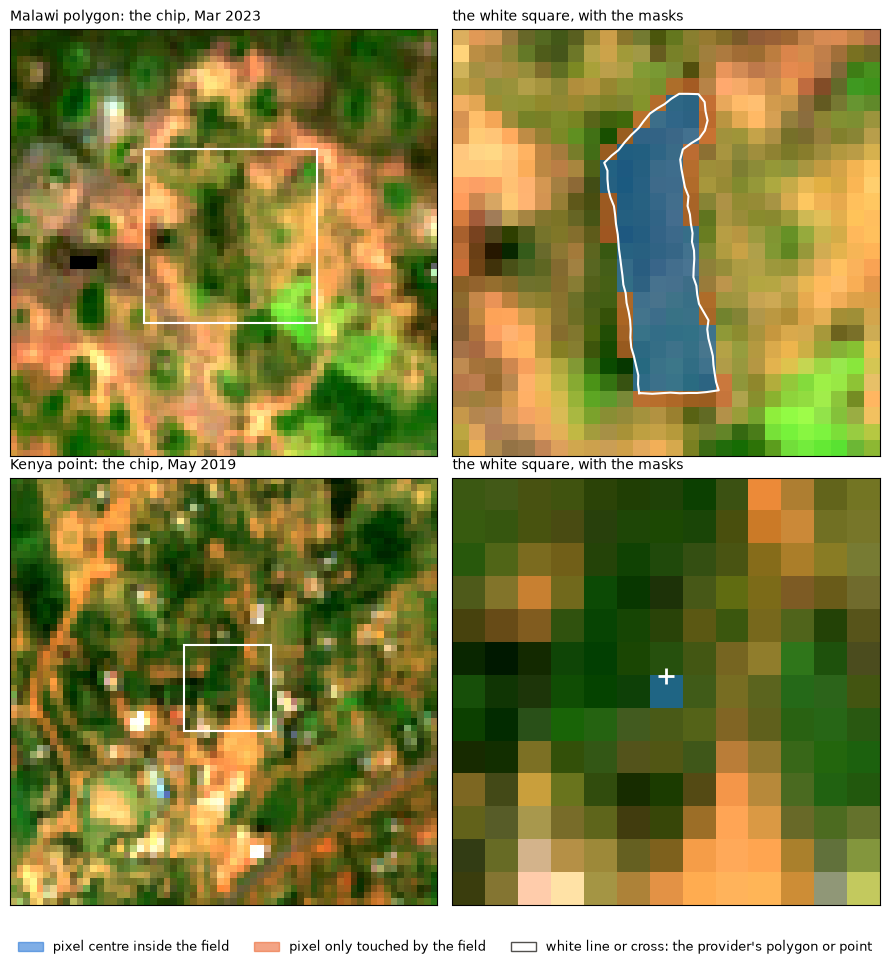

In [20]:
INSIDE, TOUCHED = to_rgb("#2a78d6"), to_rgb("#eb6834")


def greenest_scene(chip):
    '''The accepted scene of the month with the highest NDVI over the field.'''
    series = monthly_series(chip, chip.start_date, chip.end_date)
    month = vegetation_indices(series)["ndvi"].idxmax()
    item_id = series.item_ids[series.months.index(month)]
    return next(scene for scene in chip.scenes if scene.item_id == item_id)


def true_colour(chip, scene):
    rgb = np.stack([scene.reflectance[chip.bands.index(band)] for band in ("B04", "B03", "B02")], axis=-1)
    low, high = np.nanpercentile(rgb, [2, 98])
    return np.nan_to_num(np.clip((rgb - low) / (high - low), 0, 1))


def field_shape(chip):
    '''The field in chip pixels: a list of outlines for a polygon, or one (column, row) for a point.'''
    meta = json.loads(Path(filesystem_path(chip.record_dir / "record.json")).read_text(encoding="utf-8"))
    geometry = shape(transform_geom("EPSG:4326", chip.crs, meta["record"]["geometry"]))
    to_pixel = ~Affine(*chip.transform)
    if geometry.geom_type == "Point":
        return to_pixel * (geometry.x, geometry.y)
    return [np.array([to_pixel * point for point in part.exterior.coords]) for part in getattr(geometry, "geoms", [geometry])]


def draw_chip(chip, name, whole, zoom):
    scene = greenest_scene(chip)
    size = chip.aoi.shape[0]
    rows, columns = np.nonzero(chip.aoi)
    centre = (columns.min() + columns.max() + 1) / 2, (rows.min() + rows.max() + 1) / 2
    half = max(columns.max() - columns.min() + 7, rows.max() - rows.min() + 7, 13) / 2
    overlay = np.zeros((*chip.aoi.shape, 4))
    overlay[chip.aoi & ~chip.aoi_interior] = (*TOUCHED, 0.6)
    overlay[chip.aoi_interior] = (*INSIDE, 0.6)
    image = true_colour(chip, scene)
    drawn = field_shape(chip)
    whole.imshow(image, extent=(0, size, size, 0), interpolation="nearest")
    whole.add_patch(Rectangle((centre[0] - half, centre[1] - half), 2 * half, 2 * half, fill=False, color="white", linewidth=1.5))
    whole.set_title(f"{name}: the chip, {scene.date:%b %Y}", fontsize=10, loc="left")
    zoom.imshow(image, extent=(0, size, size, 0), interpolation="nearest")
    zoom.imshow(overlay, extent=(0, size, size, 0), interpolation="nearest")
    if isinstance(drawn, list):
        for outline in drawn:
            zoom.plot(outline[:, 0], outline[:, 1], color="white", linewidth=1.5)
    else:
        zoom.plot(*drawn, marker="+", markersize=12, markeredgewidth=2, color="white")
    zoom.set_xlim(centre[0] - half, centre[0] + half)
    zoom.set_ylim(centre[1] + half, centre[1] - half)
    zoom.set_title("the white square, with the masks", fontsize=10, loc="left")
    for axis in (whole, zoom):
        axis.set_xticks([])
        axis.set_yticks([])


drawn_chips = {name: chip_of(record) for name, record in (("Malawi polygon", POLYGON_RECORD), ("Kenya point", POINT_RECORD))}
if all(drawn_chips.values()):
    figure, axes = plt.subplots(2, 2, figsize=(9, 9.6))
    for (name, chip), row in zip(drawn_chips.items(), axes):
        draw_chip(chip, name, *row)
        print(f"{name}: {chip.obs_id}. Field pixels: {int(field_mask(chip).sum())}. Touched pixels: {int(chip.aoi.sum())}.")
    figure.legend(handles=[Patch(color=INSIDE, alpha=0.6, label="pixel centre inside the field"),
                           Patch(color=TOUCHED, alpha=0.6, label="pixel only touched by the field"),
                           Patch(facecolor="white", edgecolor="#52514e", label="white line or cross: the provider's polygon or point")],
                  loc="lower center", ncol=3, frameon=False, fontsize=9)
    figure.tight_layout(rect=(0, 0.04, 1, 1))
    display(figure)
    plt.close(figure)
else:
    say_missing("the chips of the two default records")

### 5. Time: which months does each field use?

**Files:** `src/cropyield/data/cohorts.py` (`COHORTS`, `season_window`), the table `coverage`.

Each cohort has one fixed season window per harvest year. A row's own planting or harvest date never moves its window. So the window can start before planting and end after harvest, and it can also end before a late harvest.

The first table compares the windows with the real dates. It needs no database.

The second table gives the state of each window month for the model rows:

- **clear:** a scene passed the clear gate of section 6.
- **cloudy:** each scene tried failed the gate.
- **no_scene:** the catalogue offered no scene for this month.
- **download_error:** the download failed part-way. No band value comes from such a folder.

The last lines of the second cell list the catalogue gaps: months where most fields have no scene. Collection 1 holds almost no scenes there. These are the two gaps of `docs/DATA.md`, early 2019 for Kenya and late 2022 for Malawi and Lacuna. They are gaps in the catalogue, not faults of the download.

In [21]:
def date_span(dates):
    '''From the 5th to the 95th percentile of some dates.'''
    if dates.empty:
        return "no dates"
    return f"{dates.quantile(0.05):%d %b %Y} to {dates.quantile(0.95):%d %b %Y}"


windows = []
for (cohort, year), rows in PRIMARY.groupby(["cohort", "season_year"], sort=False):
    start, end = rows["season_start"].iloc[0], rows["season_end"].iloc[0]
    dated = rows["obs_date"].dropna()
    after, before = int((dated > end).sum()), int((dated < start).sum())
    assert after + before == rows["date_outside_window"].sum(), f"{cohort} {year}: date flags differ"
    windows.append({"cohort": cohort, "year": str(year), "window": f"{start:%d %b %Y} to {end:%d %b %Y}",
                    "months": len(month_range(start.date(), end.date())),
                    "planting, 5 to 95 %": date_span(rows["plant_date"].dropna()),
                    "harvest or cut, 5 to 95 %": date_span(dated),
                    "date source": ", ".join(sorted(rows["obs_date_source"].unique())),
                    "rows dated after the window": after, "rows dated before it": before})
show(pd.DataFrame(windows), "Fixed windows against the real dates, on the model rows")

**Fixed windows against the real dates, on the model rows**

| cohort | year | window | months | planting, 5 to 95 % | harvest or cut, 5 to 95 % | date source | rows dated after the window | rows dated before it |
|---|---|---|---|---|---|---|---|---|
| malawi_2023 | 2023 | 01 Oct 2022 to 30 Jun 2023 | 9 | no dates | 17 May 2023 to 26 May 2023 | crop_cut_time | 0 | 0 |
| kenya_oaf_2019_2020 | 2019 | 01 Feb 2019 to 30 Sep 2019 | 8 | 19 Feb 2019 to 04 May 2019 | 10 Jul 2019 to 30 Nov 2019 | harvest_date | 416 | 0 |
| kenya_oaf_2019_2020 | 2020 | 01 Feb 2020 to 30 Sep 2020 | 8 | 07 Feb 2020 to 21 Apr 2020 | 05 Jul 2020 to 25 Nov 2020 | harvest_date, none | 434 | 0 |
| zimbabwe_lacuna_2022_2023 | 2023 | 01 Oct 2022 to 30 Jun 2023 | 9 | 02 Nov 2022 to 03 Jan 2023 | 23 Mar 2023 to 04 Jun 2023 | harvest_date | 2 | 0 |
| zimbabwe_2024 | 2024 | 01 Oct 2023 to 30 Jun 2024 | 9 | no dates | 10 Apr 2024 to 10 May 2024 | photo_filename | 0 | 0 |

In [22]:
GAP_SHARE = 0.5  # a month is a catalogue gap when more than this share of the fields has no scene
STATES = ["clear", "cloudy", "no_scene", "download_error"]

if HAS_DB:
    states = sql('''SELECT v.cohort, v.season_year::VARCHAR AS year, c.month, c.state, count(*) AS n
                    FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE v.include_primary GROUP BY ALL''')
    months = (states.pivot_table(index=["cohort", "year", "month"], columns="state", values="n", fill_value=0)
              .reindex(columns=STATES, fill_value=0).astype(int))
    months["fields"] = months[STATES].sum(axis=1)
    months["clear share"] = months["clear"] / months["fields"]
    months = months.reset_index()
    show(months, "State of each month, on the model rows")
    total = int(sql("SELECT count(*) AS n FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE v.include_primary")["n"][0])
    assert months[STATES].to_numpy().sum() == total, "the table differs from the coverage table"
    print(f"The check holds. The table adds up to the {total:,} coverage rows of the model rows.")
    gaps = months[months["no_scene"] > GAP_SHARE * months["fields"]]
    for (cohort, year), rows in gaps.groupby(["cohort", "year"]):
        print(f"Catalogue gap, {cohort} {year}: {', '.join(rows['month'])}.")
else:
    say_missing()

**State of each month, on the model rows**

| cohort | year | month | clear | cloudy | no_scene | download_error | fields | clear share |
|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | 2019 | 2019-02 | 0 | 0 | 1,768 | 0 | 1,768 | 0 |
| kenya_oaf_2019_2020 | 2019 | 2019-03 | 1,768 | 0 | 0 | 0 | 1,768 | 1 |
| kenya_oaf_2019_2020 | 2019 | 2019-04 | 1,758 | 10 | 0 | 0 | 1,768 | 0.994 |
| kenya_oaf_2019_2020 | 2019 | 2019-05 | 1,763 | 5 | 0 | 0 | 1,768 | 0.997 |
| kenya_oaf_2019_2020 | 2019 | 2019-06 | 1,609 | 159 | 0 | 0 | 1,768 | 0.91 |
| kenya_oaf_2019_2020 | 2019 | 2019-07 | 1,766 | 2 | 0 | 0 | 1,768 | 0.999 |
| kenya_oaf_2019_2020 | 2019 | 2019-08 | 1,758 | 10 | 0 | 0 | 1,768 | 0.994 |
| kenya_oaf_2019_2020 | 2019 | 2019-09 | 1,765 | 3 | 0 | 0 | 1,768 | 0.998 |
| kenya_oaf_2019_2020 | 2020 | 2020-02 | 2,204 | 5 | 0 | 0 | 2,209 | 0.998 |
| kenya_oaf_2019_2020 | 2020 | 2020-03 | 2,182 | 27 | 0 | 0 | 2,209 | 0.988 |
| kenya_oaf_2019_2020 | 2020 | 2020-04 | 2,194 | 15 | 0 | 0 | 2,209 | 0.993 |
| kenya_oaf_2019_2020 | 2020 | 2020-05 | 2,208 | 1 | 0 | 0 | 2,209 | 1 |
| kenya_oaf_2019_2020 | 2020 | 2020-06 | 2,185 | 24 | 0 | 0 | 2,209 | 0.989 |
| kenya_oaf_2019_2020 | 2020 | 2020-07 | 2,132 | 77 | 0 | 0 | 2,209 | 0.965 |
| kenya_oaf_2019_2020 | 2020 | 2020-08 | 2,008 | 201 | 0 | 0 | 2,209 | 0.909 |
| kenya_oaf_2019_2020 | 2020 | 2020-09 | 2,182 | 27 | 0 | 0 | 2,209 | 0.988 |
| malawi_2023 | 2023 | 2022-10 | 0 | 0 | 260 | 0 | 260 | 0 |
| malawi_2023 | 2023 | 2022-11 | 0 | 0 | 260 | 0 | 260 | 0 |
| malawi_2023 | 2023 | 2022-12 | 116 | 144 | 0 | 0 | 260 | 0.446 |
| malawi_2023 | 2023 | 2023-01 | 179 | 81 | 0 | 0 | 260 | 0.688 |
| malawi_2023 | 2023 | 2023-02 | 210 | 50 | 0 | 0 | 260 | 0.808 |
| malawi_2023 | 2023 | 2023-03 | 132 | 128 | 0 | 0 | 260 | 0.508 |
| malawi_2023 | 2023 | 2023-04 | 230 | 30 | 0 | 0 | 260 | 0.885 |
| malawi_2023 | 2023 | 2023-05 | 260 | 0 | 0 | 0 | 260 | 1 |
| malawi_2023 | 2023 | 2023-06 | 260 | 0 | 0 | 0 | 260 | 1 |
| zimbabwe_2024 | 2024 | 2023-10 | 2,457 | 1 | 0 | 0 | 2,458 | 1 |
| zimbabwe_2024 | 2024 | 2023-11 | 2,453 | 5 | 0 | 0 | 2,458 | 0.998 |
| zimbabwe_2024 | 2024 | 2023-12 | 2,427 | 31 | 0 | 0 | 2,458 | 0.987 |
| zimbabwe_2024 | 2024 | 2024-01 | 2,296 | 162 | 0 | 0 | 2,458 | 0.934 |
| zimbabwe_2024 | 2024 | 2024-02 | 2,452 | 6 | 0 | 0 | 2,458 | 0.998 |
| zimbabwe_2024 | 2024 | 2024-03 | 2,426 | 32 | 0 | 0 | 2,458 | 0.987 |
| zimbabwe_2024 | 2024 | 2024-04 | 2,456 | 2 | 0 | 0 | 2,458 | 0.999 |
| zimbabwe_2024 | 2024 | 2024-05 | 2,458 | 0 | 0 | 0 | 2,458 | 1 |
| zimbabwe_2024 | 2024 | 2024-06 | 2,458 | 0 | 0 | 0 | 2,458 | 1 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2022-10 | 0 | 0 | 1,880 | 0 | 1,880 | 0 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2022-11 | 0 | 0 | 1,880 | 0 | 1,880 | 0 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2022-12 | 1,791 | 89 | 0 | 0 | 1,880 | 0.953 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-01 | 1,502 | 378 | 0 | 0 | 1,880 | 0.799 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-02 | 1,390 | 490 | 0 | 0 | 1,880 | 0.739 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-03 | 1,687 | 193 | 0 | 0 | 1,880 | 0.897 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-04 | 1,880 | 0 | 0 | 0 | 1,880 | 1 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-05 | 1,880 | 0 | 0 | 0 | 1,880 | 1 |
| zimbabwe_lacuna_2022_2023 | 2023 | 2023-06 | 1,880 | 0 | 0 | 0 | 1,880 | 1 |

The check holds. The table adds up to the 73,198 coverage rows of the model rows.
Catalogue gap, kenya_oaf_2019_2020 2019: 2019-02.
Catalogue gap, malawi_2023 2023: 2022-10, 2022-11.
Catalogue gap, zimbabwe_lacuna_2022_2023 2023: 2022-10, 2022-11.


### 6. Scenes: how is one scene chosen per month?

**File:** `scripts/step5_download_imagery.py`.

The downloader keeps at most one scene per month. The first table gives the rule, with the values that the code uses.

**Tile cloud is not field cloud.** The sort uses the cloud of the whole tile. A scene with little cloud on the tile can still be cloudy over one field. So the first scene tried can fail the gate, and a later scene can pass.

**An error moves to the next scene.** A read that fails counts as a failed try. If a later scene of the month passes, that scene is kept, and the record can still end as `complete`. The compare cell of Step 2 names such a record.

The second table counts each try, from the `record.json` of each record on disk. Long flaw counts stay for Step 4.

In [23]:
longest_window = max(len(month_range(start.date(), end.date())) for start, end in zip(LABELS["season_start"], LABELS["season_end"]))
assert longest_window < RULES.max_scenes
show(pd.DataFrame([
    ("Search", f"Collection `{downloader.COLLECTION}` on Earth Search. Tile cloud at most {RULES.max_cloud_cover:g} %. Date inside the window. The tile covers the field point.", "`Catalog.search`"),
    ("Order", f"Per month, sort by whole-tile cloud, then date, then id. Keep the first {RULES.candidates_per_month}.", "`month_candidates`"),
    ("Clear gate", f"A pixel is clear when its SCL class is vegetation, bare soil or water. At least {RULES.min_clear_fraction:g} of the touched mask must be clear. The gate runs on SCL, then again when all bands are read.", "`download_scene`"),
    ("Choice", "The first scene that passes wins, and the month stops there.", "`process_record`"),
    ("Failure", "A failed read moves to the next scene of the month. With no next scene the month stays empty.", "`process_record`"),
    ("Limit", f"At most {RULES.max_scenes} months per record. The longest window has {longest_window} months, so this limit never acts.", "`month_candidates`"),
], columns=["part", "rule", "code"]), "The scene rule")

if HAS_DB:
    records = sql("SELECT d.obs_id, d.record_dir, l.cohort FROM downloads d JOIN labels l USING (obs_id)")

    def read_record(stored):
        return json.loads(Path(filesystem_path(chip_path(stored) / "record.json")).read_text(encoding="utf-8"))

    with ThreadPoolExecutor(8) as pool:
        metas = list(pool.map(read_record, records["record_dir"]))
    window_basis = Counter(meta["record"]["window_basis"] for meta in metas)
    tries = pd.DataFrame([(cohort, obs_id, attempt["month"], attempt["status"])
                          for cohort, obs_id, meta in zip(records["cohort"], records["obs_id"], metas)
                          for attempt in meta["attempts"]], columns=["cohort", "obs_id", "month", "status"])
    del metas
    tries["accepted"], tries["error"] = tries["status"] == "accepted", tries["status"] == "error"
    per_month = (tries.groupby(["cohort", "obs_id", "month"], sort=False)
                 .agg(tried=("accepted", "size"), accepted=("accepted", "max"), errors=("error", "sum")).reset_index())
    per_month["at_first"] = per_month["accepted"] & (per_month["tried"] == 1)
    per_month["after_error"] = per_month["accepted"] & (per_month["errors"] > 0)
    table = per_month.groupby("cohort").agg(**{"months tried": ("tried", "size"), "passed at the first try": ("at_first", "sum"),
                                               "passed": ("accepted", "sum"), "passed after an error": ("after_error", "sum")})
    table["passed at a later try"] = table["passed"] - table["passed at the first try"]
    table["no scene passed"] = table["months tried"] - table["passed"]
    status = tries.pivot_table(index="cohort", columns="status", values="month", aggfunc="size", fill_value=0)
    for column, name in (("rejected_cloud_or_nodata", "tries: cloud"), ("rejected_band_nodata", "tries: band gap"), ("error", "tries: error")):
        table[name] = status[column] if column in status else 0
    show(table.drop(columns="passed").reset_index(), "Each scene tried, from record.json")
    assert per_month["accepted"].sum() == int(sql("SELECT count(*) AS n FROM scenes")["n"][0]), "record.json differs from the scenes table"
    print("The check holds. The accepted tries equal the rows of the scenes table.")
else:
    say_missing()

**The scene rule**

| part | rule | code |
|---|---|---|
| Search | Collection `sentinel-2-c1-l2a` on Earth Search. Tile cloud at most 80 %. Date inside the window. The tile covers the field point. | `Catalog.search` |
| Order | Per month, sort by whole-tile cloud, then date, then id. Keep the first 3. | `month_candidates` |
| Clear gate | A pixel is clear when its SCL class is vegetation, bare soil or water. At least 0.8 of the touched mask must be clear. The gate runs on SCL, then again when all bands are read. | `download_scene` |
| Choice | The first scene that passes wins, and the month stops there. | `process_record` |
| Failure | A failed read moves to the next scene of the month. With no next scene the month stays empty. | `process_record` |
| Limit | At most 12 months per record. The longest window has 9 months, so this limit never acts. | `month_candidates` |

**Each scene tried, from record.json**

| cohort | months tried | passed at the first try | passed after an error | passed at a later try | no scene passed | tries: cloud | tries: band gap | tries: error |
|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | 30,048 | 27,584 | 1 | 1,898 | 566 | 4,031 | 0 | 1 |
| malawi_2022 | 1,696 | 1,537 | 0 | 54 | 105 | 167 | 0 | 0 |
| malawi_2023 | 1,820 | 1,157 | 0 | 230 | 433 | 1,273 | 0 | 0 |
| zimbabwe_2024 | 38,988 | 37,400 | 8 | 1,118 | 470 | 2,753 | 0 | 8 |
| zimbabwe_lacuna_2022_2023 | 15,337 | 13,027 | 1 | 962 | 1,348 | 4,810 | 0 | 1 |

The check holds. The accepted tries equal the rows of the scenes table.


### 7. Bands: how do pixels become one value?

**Files:** `scripts/step5_download_imagery.py` (`read_asset`, `download_scene`), `src/cropyield/satellite/monthly.py` (`monthly_series`).

1. **Bands.** We keep the bands of the table below, and the scene classes in SCL.
2. **Resampling.** Each band is read onto the same chip grid. A band with coarser pixels gets bilinear resampling, so it is smoothed. SCL gets nearest neighbour, because its values are classes.
3. **Scale.** Reflectance = DN x scale + offset. The values come from the STAC item. The chip stores the result, so it is not done twice.
4. **Valid pixels.** A pixel is valid when its SCL class is clear and all bands have a value.
5. **Field-month value.** For each band, the median over the pixels that are both field pixels and valid. The median runs per band, so two bands can come from different pixels.

A month with no valid field pixel stays NULL.

The second cell recomputes each month of one polygon and one point from the chip, and compares with the table `monthly_bands`.

In [24]:
band_rows = [{"band": band, "asset": asset} for band, asset in downloader.BANDS.items()]
known_chip = next(filter(None, (chip_of(record) for record in (POINT_RECORD, POLYGON_RECORD))), None)
if known_chip:
    item_id = known_chip.scenes[0].item_id
    scene_file = Path(filesystem_path(known_chip.record_dir / item_id / "scene.json"))
    assets = json.loads(scene_file.read_text(encoding="utf-8"))["item"]["assets"]
    for row in band_rows:
        info = assets[row["asset"]]
        raster = info["raster:bands"][0]
        row.update({"centre, nm": round(info["eo:bands"][0]["center_wavelength"] * 1000), "native pixel, m": raster["spatial_resolution"],
                    "scale": f"{raster['scale']:g}", "offset": f"{raster['offset']:g}", "nodata": raster["nodata"],
                    "to the chip": "as it is" if raster["spatial_resolution"] == RULES.resolution else "bilinear"})
    raster = assets["scl"]["raster:bands"][0]
    band_rows.append({"band": "SCL", "asset": "scl", "native pixel, m": raster["spatial_resolution"], "nodata": raster["nodata"], "to the chip": "nearest"})
    print(f"Read from the STAC item of {item_id}.")
else:
    print("No chip on this copy, so the table holds only the band names.")
show(pd.DataFrame(band_rows).astype("object"), "The bands we keep")

Read from the STAC item of S2A_T36NXF_20190323T080452_L2A.


**The bands we keep**

| band | asset | centre, nm | native pixel, m | scale | offset | nodata | to the chip |
|---|---|---|---|---|---|---|---|
| B02 | blue | 490 | 10 | 0.0001 | -0.1 | 0 | as it is |
| B03 | green | 560 | 10 | 0.0001 | -0.1 | 0 | as it is |
| B04 | red | 665 | 10 | 0.0001 | -0.1 | 0 | as it is |
| B05 | rededge1 | 704 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| B06 | rededge2 | 740 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| B07 | rededge3 | 783 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| B08 | nir | 842 | 10 | 0.0001 | -0.1 | 0 | as it is |
| B8A | nir08 | 865 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| B11 | swir16 | 1,610 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| B12 | swir22 | 2,190 | 20 | 0.0001 | -0.1 | 0 | bilinear |
| SCL | scl |  | 20 |  |  | 0 | nearest |

In [25]:
def recompute_bands(obs_id):
    '''Each month of one record, from the chip: the median over field and valid pixels, and the database row.'''
    chip = chip_of(obs_id)
    stored = sql("SELECT * FROM monthly_bands WHERE obs_id = ? ORDER BY month", obs_id).set_index("month")
    columns = [band.lower() for band in chip.bands]
    field, rows = field_mask(chip), {}
    for scene in chip.scenes:
        pixels = field & scene.valid
        if pixels.any():
            rows[scene.date.strftime("%Y-%m")] = np.median(scene.reflectance[:, pixels], axis=1)
    frame = pd.DataFrame(rows, index=columns).T
    assert frame.index.tolist() == stored.index[~stored["missing"]].tolist(), f"{obs_id}: months differ"
    return frame, stored.loc[frame.index, columns].astype("float64")


if chip_of(POLYGON_RECORD) and chip_of(POINT_RECORD):
    for name, record in (("Malawi polygon", POLYGON_RECORD), ("Kenya point", POINT_RECORD)):
        computed, stored_values = recompute_bands(record)
        gap = float((computed - stored_values).abs().to_numpy().max())
        assert gap <= TOLERANCE, f"{record}: largest gap {gap}"
        month = computed.index[0]
        show(pd.DataFrame({"band": computed.columns, "from the chip": [f"{value:.6f}" for value in computed.loc[month]],
                           "monthly_bands": [f"{value:.6f}" for value in stored_values.loc[month]]}),
             f"{name}, {month}. Valid field pixels: {int(sql('SELECT field_pixels FROM monthly_bands WHERE obs_id = ? AND month = ?', record, month).iloc[0, 0])}")
        print(f"The check holds. {name}: {len(computed)} months and {computed.shape[1]} bands, largest gap {gap:.1e}, limit {TOLERANCE:g}.")
else:
    say_missing("the chips of the two default records")

**Malawi polygon, 2023-01. Valid field pixels: 79**

| band | from the chip | monthly_bands |
|---|---|---|
| b02 | 0.114000 | 0.114000 |
| b03 | 0.149000 | 0.149000 |
| b04 | 0.179800 | 0.179800 |
| b05 | 0.219650 | 0.219650 |
| b06 | 0.278031 | 0.278031 |
| b07 | 0.313119 | 0.313119 |
| b08 | 0.283600 | 0.283600 |
| b8a | 0.333100 | 0.333100 |
| b11 | 0.415538 | 0.415538 |
| b12 | 0.389688 | 0.389688 |

The check holds. Malawi polygon: 5 months and 10 bands, largest gap 0.0e+00, limit 1e-06.


**Kenya point, 2019-03. Valid field pixels: 1**

| band | from the chip | monthly_bands |
|---|---|---|
| b02 | 0.059200 | 0.059200 |
| b03 | 0.103200 | 0.103200 |
| b04 | 0.158200 | 0.158200 |
| b05 | 0.170656 | 0.170656 |
| b06 | 0.222994 | 0.222994 |
| b07 | 0.247525 | 0.247525 |
| b08 | 0.244000 | 0.244000 |
| b8a | 0.263012 | 0.263012 |
| b11 | 0.304669 | 0.304669 |
| b12 | 0.236337 | 0.236337 |

The check holds. Kenya point: 7 months and 10 bands, largest gap 0.0e+00, limit 1e-06.


### 8. Indices: what is each formula?

**File:** `src/cropyield/features/indices.py`.

The cell reads each formula from the code. An index comes from the field-month values of section 7, so it is a formula on band medians, not a median of pixel indices.

**MTCI and NDVI705 use B08 here.** The usual MTCI uses B06 where this one uses B08. So a value here does not equal a published MTCI. We keep the code as it is, and it stays one rule for all cohorts.

A month with a missing band gives NULL. A zero denominator also gives NULL, never infinity.

In [26]:
source = (ROOT / "src" / "cropyield" / "features" / "indices.py").read_text(encoding="utf-8")
formulas = {name: re.sub(r'b\["(\w+)"\]', r"\1", text) for name, text in re.findall(r'^\s+"(\w+)": (.+),$', source, flags=re.MULTILINE)}
assert tuple(formulas) == INDICES, "the code has other indices"

USUAL = {"mtci": "(B06 - B05) / (B05 - B04)"}
show(pd.DataFrame([(name.upper(), f"`{text}`", ", ".join(sorted(set(re.findall(r"B\d\w", text)))),
                    f"`{USUAL[name]}`" if name in USUAL else "") for name, text in formulas.items()],
                  columns=["index", "formula in the code", "bands", "usual formula, where it differs"]), "Read from the code")

if chip_of(POLYGON_RECORD) and chip_of(POINT_RECORD):
    for name, record in (("Malawi polygon", POLYGON_RECORD), ("Kenya point", POINT_RECORD)):
        computed, _ = recompute_bands(record)
        bands = computed.astype("float64").rename(columns=str.upper)
        own = pd.DataFrame({index: eval(text, {}, {band: bands[band] for band in bands}) for index, text in formulas.items()})
        stored_values = sql("SELECT * FROM vegetation_indices WHERE obs_id = ?", record).set_index("month").loc[own.index, list(INDICES)]
        gap = float((own - stored_values).abs().to_numpy().max())
        assert gap <= TOLERANCE, f"{record}: largest gap {gap}"
        print(f"The check holds. {name}: {len(own)} months and {own.shape[1]} indices, largest gap {gap:.1e}, limit {TOLERANCE:g}.")
else:
    say_missing("the chips of the two default records")

**Read from the code**

| index | formula in the code | bands | usual formula, where it differs |
|---|---|---|---|
| NDVI | `(B08 - B04) / (B08 + B04)` | B04, B08 |  |
| GCVI | `B08 / B03 - 1` | B03, B08 |  |
| MTCI | `(B08 - B05) / (B05 - B04)` | B04, B05, B08 | `(B06 - B05) / (B05 - B04)` |
| NDVI705 | `(B08 - B05) / (B08 + B05)` | B05, B08 |  |
| NDVI740 | `(B08 - B06) / (B08 + B06)` | B06, B08 |  |

The check holds. Malawi polygon: 5 months and 5 indices, largest gap 0.0e+00, limit 1e-06.
The check holds. Kenya point: 7 months and 5 indices, largest gap 0.0e+00, limit 1e-06.


### 9. Season values: how are months combined?

**File:** `sql/views.sql` (the views `season_indices` and `master`).

For each field, `season_indices` takes the maximum and the mean of each index over the months that have a value. A NULL month is skipped. It is not a zero and it is not filled. `months_with_data` counts the months with a value.

Three things follow, and the table shows each one:

- **Month sets differ per field.** The maximum can come from a clear month that another field does not have. So a season value can partly say which month was clear.
- **The sets differ per year.** The Kenya 2019 window has no scene in its first month, so a Kenya 2019 mean has one month fewer than a Kenya 2020 mean.
- **Months after the harvest are inside.** The window is fixed, so a field can have clear months after its own harvest or cut. Those months can show bare soil. The table counts by whole month after the month of `obs_date`.

The table also shows how many model rows fall below the clear-month rule. Those rows stay in `labels_v1` and leave only the X and Y rows of Step 4.

In [27]:
if HAS_DB:
    seasons = sql('''
        WITH months AS (
            SELECT obs_id, count(*) AS window_months, count(*) FILTER (WHERE NOT missing) AS with_data,
                   string_agg(month, ' ' ORDER BY month) FILTER (WHERE NOT missing) AS month_set
            FROM monthly_bands GROUP BY obs_id
        ), late AS (
            SELECT c.obs_id, count(*) AS clear_months,
                   count(*) FILTER (WHERE c.month > strftime(v.obs_date, '%Y-%m')) AS after_harvest
            FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE c.state = 'clear' GROUP BY c.obs_id
        )
        SELECT v.cohort, v.season_year::VARCHAR AS year, count(*) AS fields, max(window_months) AS "window months",
               count(DISTINCT month_set) AS "different month sets", min(with_data) AS "fewest months",
               median(with_data) AS "median months", max(with_data) AS "most months",
               count(*) FILTER (WHERE with_data < ?) AS "rows below the rule",
               sum(clear_months)::BIGINT AS "clear months", sum(after_harvest)::BIGINT AS "clear months after the harvest month"
        FROM months JOIN labels_v1 v USING (obs_id) LEFT JOIN late USING (obs_id)
        WHERE v.include_primary GROUP BY ALL ORDER BY 1, 2''', MIN_MONTHS)
    show(seasons, f"Season values on the model rows, with the rule at {MIN_MONTHS} clear months")

    february = int(sql('''SELECT count(*) AS n FROM monthly_bands b JOIN labels_v1 v USING (obs_id)
                          WHERE v.cohort = 'kenya_oaf_2019_2020' AND b.month = '2019-02' AND NOT b.missing''')["n"][0])
    assert february == 0, "Kenya 2019 has a February value"
    print("The check holds. Kenya 2019 has no February value.")
    if FULL_COPY:
        below = dict(seasons.groupby("cohort")["rows below the rule"].sum())
        assert below == {"kenya_oaf_2019_2020": 0, "malawi_2023": 9, "zimbabwe_2024": 0, "zimbabwe_lacuna_2022_2023": 0}
        print(f"The check holds. The clear-month rule touches {below['malawi_2023']} Malawi rows and no other row.")

    for name, record in (("Malawi polygon", POLYGON_RECORD), ("Kenya point", POINT_RECORD)):
        monthly_values = sql("SELECT * FROM vegetation_indices WHERE obs_id = ?", record)[list(INDICES)]
        columns = [f"{index}_season_{stat}" for index in INDICES for stat in ("max", "mean")]
        stored_season = sql(f"SELECT {', '.join(columns)} FROM master WHERE obs_id = ?", record).iloc[0]
        own = pd.Series({f"{index}_season_{stat}": getattr(monthly_values[index], stat)() for index in INDICES for stat in ("max", "mean")})
        assert (own - stored_season).abs().max() <= TOLERANCE, f"{record}: season values differ"
        print(f"The check holds. {name}: max and mean over {monthly_values['ndvi'].notna().sum()} of {len(monthly_values)} months equal master.")
else:
    say_missing()

**Season values on the model rows, with the rule at 4 clear months**

| cohort | year | fields | window months | different month sets | fewest months | median months | most months | rows below the rule | clear months | clear months after the harvest month |
|---|---|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | 2019 | 1,768 | 8 | 9 | 5 | 7 | 7 | 0 | 12,187 | 1,631 |
| kenya_oaf_2019_2020 | 2020 | 2,209 | 8 | 28 | 4 | 8 | 8 | 0 | 17,295 | 2,205 |
| malawi_2023 | 2023 | 260 | 9 | 26 | 2 | 5 | 7 | 9 | 1,387 | 260 |
| zimbabwe_2024 | 2024 | 2,458 | 9 | 10 | 5 | 9 | 9 | 0 | 21,883 | 4,513 |
| zimbabwe_lacuna_2022_2023 | 2023 | 1,880 | 9 | 13 | 4 | 7 | 7 | 0 | 12,010 | 2,879 |

The check holds. Kenya 2019 has no February value.
The check holds. The clear-month rule touches 9 Malawi rows and no other row.
The check holds. Malawi polygon: max and mean over 5 of 9 months equal master.
The check holds. Kenya point: max and mean over 7 of 8 months equal master.


### 10. Defaults and fills: what did we fill in?

**Files:** the sections above. The table names the file of each default.

**No imputation exists.** No month gets a value from another month, another field or a model. The last check of this section proves it. A month with no clear scene stays NULL, and season values skip it.

Some values are still choices. The table lists each default, where it lives, and how many rows it touches. A count of zero means the rule exists, and no row needed it.

In [28]:
def database_count(query, *params):
    return int(sql(query, *params).iloc[0, 0]) if HAS_DB else "needs the database"


kenya_rows = LABELS["cohort"] == "kenya_oaf_2019_2020"
lacuna_mask = LABELS["cohort"] == "zimbabwe_lacuna_2022_2023"
fallback_date = ~LABELS["obs_date_source"].isin(["harvest_date", "none"])
window_fallbacks = sum(count for basis, count in window_basis.items() if basis != "user_override") if HAS_DB else "needs the database"
polygon_months = database_count('''SELECT count(*) FROM monthly_bands b JOIN downloads d USING (obs_id)
                                   WHERE d.aoi_type = 'field_polygon' AND b.field_pixels = 1''')

defaults = pd.DataFrame([
    ("Cut size, number of cuts and moisture are one constant per cohort", "`src/cropyield/data/labels.py`, `MEASUREMENTS`", len(LABELS), "declared, not measured"),
    ("Kenya 2020 takes the Kenya 2019 box size", "`src/cropyield/data/labels.py`, `MEASUREMENTS`", int((kenya_rows & (LABELS["season_year"] == 2020)).sum()), "an assumption: the provider does not state it"),
    ("A cohort with no stated moisture keeps NULL", "`src/cropyield/data/labels.py`, `MEASUREMENTS`", int(LABELS["moisture_basis_pct"].isna().sum()), "left empty"),
    ("A Kenya row with no kg/ha takes kg/acre", "`scripts/step2_audit_labels.py`, `oaf_full`", int(LABELS.loc[kenya_rows, "source_flags"].str.contains("yield_converted_from_kg_per_acre").sum()), "the rule never acted"),
    (f"Kenya `field_area_ha` is `plot_acres` x {ACRE_HA}", "`src/cropyield/data/labels.py`, `cohort_frame`", int(LABELS.loc[kenya_rows, "field_area_ha"].notna().sum()), "a unit change"),
    ("`obs_date` takes the harvest date, else the crop-cut or photo date", "`src/cropyield/data/labels.py`, `cohort_frame`", int(fallback_date.sum()), "rows on the second choice"),
    ("`obs_date` stays NULL when neither date exists", "`src/cropyield/data/labels.py`, `cohort_frame`", int(LABELS["obs_date"].isna().sum()), "left empty"),
    ("An empty intercropping or irrigation value counts as pure stand and rainfed", "`src/cropyield/data/labels.py`, `exclusion_reasons`", int((lacuna_mask & (LABELS["intercropped"].isna() | LABELS["irrigated"].isna())).sum()), "no Lacuna row is empty"),
    ("A polygon also gets one point, its `representative_point`", "`scripts/step2_audit_labels.py`, `base`", int((LABELS["geometry_type"] != "Point").sum()), "chip centre and split distances"),
    ("The fixed window replaces each date fallback of the downloader", "`scripts/step5_download_imagery.py`, `time_window`", window_fallbacks, "records that used a fallback"),
    ("A missing tile cloud value sorts as 100 %", "`scripts/step5_download_imagery.py`, `month_candidates`", database_count("SELECT count(*) FROM scenes WHERE tile_cloud_cover IS NULL"), "the rule never acted"),
    ("A polygon with no pixel centre inside uses the touched pixels", "`src/cropyield/satellite/monthly.py`, `monthly_series`", database_count("SELECT count(*) FROM downloads WHERE aoi_type = 'field_polygon' AND field_pixels = aoi_pixels"), "the rule never acted"),
    ("One valid pixel is enough for a polygon month", "`src/cropyield/satellite/monthly.py`, `min_pixels`", polygon_months, "months from one pixel"),
    ("A zero denominator in an index gives NULL", "`src/cropyield/features/indices.py`", database_count('''SELECT count(*) FROM monthly_bands b JOIN vegetation_indices v USING (obs_id, month)
        WHERE NOT b.missing AND (v.ndvi IS NULL OR v.gcvi IS NULL OR v.mtci IS NULL OR v.ndvi705 IS NULL OR v.ndvi740 IS NULL)'''), "the rule never acted"),
    ("A month with no value stays NULL", "`src/cropyield/satellite/monthly.py`, `monthly_series`", database_count("SELECT count(*) FROM monthly_bands WHERE missing"), "left empty, not filled"),
    ("A record with no band row gets `months_with_data` = 0", "`sql/views.sql`, `master`", database_count("SELECT count(*) FROM downloads d ANTI JOIN monthly_bands b USING (obs_id)"), "the rule never acted"),
], columns=["default", "where it lives", "rows", "what it means"])
show(defaults, "Each default, with its count")

if HAS_DB:
    filled = database_count('''SELECT count(*) FROM coverage c JOIN monthly_bands b USING (obs_id, month)
                               WHERE c.state <> 'clear' AND NOT b.missing''')
    assert filled == 0, "a month with no clear scene has a value"
    print(f"The check holds. {filled} months with no clear scene have a band value.")
words = re.compile(r"\b(interpolate|ffill|bfill|impute\w*|SimpleImputer)\b", re.IGNORECASE)
found = [path.relative_to(ROOT).as_posix() for folder in ("src", "scripts", "sql") for path in (ROOT / folder).rglob("*")
         if path.suffix in (".py", ".sql") and words.search(path.read_text(encoding="utf-8"))]
assert not found, f"a kept file fills values: {found}"
print("The check holds. No kept script calls an interpolation or imputation function.")

**Each default, with its count**

| default | where it lives | rows | what it means |
|---|---|---|---|
| Cut size, number of cuts and moisture are one constant per cohort | `src/cropyield/data/labels.py`, `MEASUREMENTS` | 11,364 | declared, not measured |
| Kenya 2020 takes the Kenya 2019 box size | `src/cropyield/data/labels.py`, `MEASUREMENTS` | 2,209 | an assumption: the provider does not state it |
| A cohort with no stated moisture keeps NULL | `src/cropyield/data/labels.py`, `MEASUREMENTS` | 11,104 | left empty |
| A Kenya row with no kg/ha takes kg/acre | `scripts/step2_audit_labels.py`, `oaf_full` | 0 | the rule never acted |
| Kenya `field_area_ha` is `plot_acres` x 0.40468564224 | `src/cropyield/data/labels.py`, `cohort_frame` | 3,977 | a unit change |
| `obs_date` takes the harvest date, else the crop-cut or photo date | `src/cropyield/data/labels.py`, `cohort_frame` | 5,121 | rows on the second choice |
| `obs_date` stays NULL when neither date exists | `src/cropyield/data/labels.py`, `cohort_frame` | 89 | left empty |
| An empty intercropping or irrigation value counts as pure stand and rainfed | `src/cropyield/data/labels.py`, `exclusion_reasons` | 0 | no Lacuna row is empty |
| A polygon also gets one point, its `representative_point` | `scripts/step2_audit_labels.py`, `base` | 789 | chip centre and split distances |
| The fixed window replaces each date fallback of the downloader | `scripts/step5_download_imagery.py`, `time_window` | 0 | records that used a fallback |
| A missing tile cloud value sorts as 100 % | `scripts/step5_download_imagery.py`, `month_candidates` | 0 | the rule never acted |
| A polygon with no pixel centre inside uses the touched pixels | `src/cropyield/satellite/monthly.py`, `monthly_series` | 0 | the rule never acted |
| One valid pixel is enough for a polygon month | `src/cropyield/satellite/monthly.py`, `min_pixels` | 3 | months from one pixel |
| A zero denominator in an index gives NULL | `src/cropyield/features/indices.py` | 0 | the rule never acted |
| A month with no value stays NULL | `src/cropyield/satellite/monthly.py`, `monthly_series` | 13,332 | left empty, not filled |
| A record with no band row gets `months_with_data` = 0 | `sql/views.sql`, `master` | 0 | the rule never acted |

The check holds. 0 months with no clear scene have a band value.
The check holds. No kept script calls an interpolation or imputation function.


### 11. Splits: how do we test across space and time?

**Files:** `src/cropyield/eval/splits.py`, `scripts/step4_build_splits.py`, `data/splits/`, `docs/EVALUATION.md`.

Split files are frozen before any model runs. Each file holds one row per `include_primary` row, also rows with few clear months.

| Family | Meaning | Group held out |
|---|---|---|
| `s1_cc2km` | new village | connected clusters at 2 km |
| `s2_region` | new region | the unit of `REGION_UNITS` in `scripts/step4_build_splits.py` |
| `temporal` | new season, Kenya only | none: train on one year, test on the other |
| `random_diag` | a diagnostic, optimistic on purpose | none |

**The distances show what each family blocks.** Only `s1_cc2km` keeps test and train apart by distance. The table gives the smallest test-train distance, and the test rows closer than 2 km.

**No buffer is in the files.** No file drops a training field near a test field. The rule lived in the runner, and the runner is parked. The Kenya `s2_region` row of the table proves this: it has test rows close to a training row, and a buffer would leave none. A buffer would need its own step before a model runs.

**The new-season test is not blocked in space.** Many Kenya fields of one year sit close to a field of the other year. So a new-season score mixes time and place. The `test_subset` column splits districts seen in training from new ones, but it does not block by distance.

**There are two cluster definitions.** `labels_v1.cluster_2km` was built on all rows of a cohort, also the rows the models do not use. The `s1_cc2km` groups were built on the `include_primary` rows only. A dropped row can join two clusters, so the two can differ. To keep rows together in a fold, use `group_id` of the split file, not `cluster_2km`.

In [29]:
split_manifest = json.loads((DATA / "splits" / "manifest.json").read_text(encoding="utf-8"))
assert sha256(LABELS_FILE) == split_manifest["labels_sha256"], "labels_v1 differs from the manifest"
changed = [name for name, item in split_manifest["files"].items() if sha256(DATA / "splits" / name) != item["sha256"]]
assert not changed, f"changed split files: {changed}"
print(f"The check holds. labels_v1 and all {len(split_manifest['files'])} split files equal `data/splits/manifest.json`.")
print(f"Seed {split_manifest['seed']}, {split_manifest['folds']} folds, region units {split_manifest['region_units']}.")

split_tables = {}
for path in sorted((DATA / "splits").glob("*.csv")):
    cohort, family = path.stem.split("__")
    split_tables[cohort, family] = pd.read_csv(path, dtype={"group_id": str, "fold": str, "test_subset": str})

places = PRIMARY.set_index("obs_id")[["lat", "lon"]]
split_rows = []
for (cohort, family), table in split_tables.items():
    for repeat, part in table.groupby("repeat"):
        where = places.loc[part["obs_id"]]
        lat, lon = where["lat"].to_numpy(), where["lon"].to_numpy()
        folds = sorted(set(part["fold"]) - {"train"})
        nearest = np.concatenate([nearest_km(lat, lon, (part["fold"] == fold).to_numpy(), (part["fold"] != fold).to_numpy())
                                  for fold in folds])
        sizes = part[part["fold"] != "train"].groupby("fold").size()
        split_rows.append({"cohort": cohort, "family": family, "repeat": repeat, "rows": len(part),
                           "groups": part["group_id"].nunique(), "test folds": len(folds),
                           "test rows per fold": f"{sizes.min():,} to {sizes.max():,}",
                           "smallest test-train km": round(float(nearest.min()), 3), "test rows within 2 km": int((nearest < 2).sum())})
families = pd.DataFrame(split_rows)
show(families, "The split files")

villages = families[families["family"] == "s1_cc2km"]
assert (villages["smallest test-train km"] >= 2).all(), "a new-village test field is within 2 km of a training field"
print(f"The check holds. In each s1_cc2km file the smallest test-train distance is at least 2 km; the smallest is {villages['smallest test-train km'].min():.2f} km.")
for cohort in MODEL_COHORTS:
    assert set(split_tables[cohort, "s1_cc2km"]["obs_id"]) == set(PRIMARY.loc[PRIMARY["cohort"] == cohort, "obs_id"])

clusters = []
for cohort in MODEL_COHORTS:
    rows = LABELS[LABELS["cohort"] == cohort]
    clusters.append({"cohort": cohort, "clusters over all rows": rows["cluster_2km"].nunique(),
                     "the same clusters on model rows": rows.loc[rows["include_primary"], "cluster_2km"].nunique(),
                     "groups of s1_cc2km": split_tables[cohort, "s1_cc2km"]["group_id"].nunique()})
show(pd.DataFrame(clusters), "The two cluster definitions")

The check holds. labels_v1 and all 13 split files equal `data/splits/manifest.json`.
Seed 20261029, 5 folds, region units {'malawi_2023': 5.0, 'kenya_oaf_2019_2020': 'admin_unit', 'zimbabwe_lacuna_2022_2023': 'admin_unit', 'zimbabwe_2024': 'kmeans20'}.


**The split files**

| cohort | family | repeat | rows | groups | test folds | test rows per fold | smallest test-train km | test rows within 2 km |
|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | random_diag | 0 | 3,977 | 3,977 | 5 | 795 to 796 | 0 | 3,566 |
| kenya_oaf_2019_2020 | s1_cc2km | 0 | 3,977 | 849 | 5 | 795 to 796 | 2.003 | 0 |
| kenya_oaf_2019_2020 | s2_region | 0 | 3,977 | 50 | 5 | 788 to 800 | 0.003 | 806 |
| kenya_oaf_2019_2020 | temporal | 0 | 3,977 | 50 | 1 | 2,209 to 2,209 | 0.001 | 833 |
| kenya_oaf_2019_2020 | temporal | 1 | 3,977 | 50 | 1 | 1,768 to 1,768 | 0.001 | 924 |
| malawi_2023 | random_diag | 0 | 260 | 260 | 5 | 52 to 52 | 0.005 | 241 |
| malawi_2023 | s1_cc2km | 0 | 260 | 53 | 5 | 52 to 52 | 2.214 | 0 |
| malawi_2023 | s2_region | 0 | 260 | 21 | 5 | 48 to 62 | 5.095 | 0 |
| zimbabwe_2024 | random_diag | 0 | 2,458 | 2,458 | 5 | 491 to 492 | 0.008 | 1,735 |
| zimbabwe_2024 | s1_cc2km | 0 | 2,458 | 996 | 5 | 491 to 492 | 2.004 | 0 |
| zimbabwe_2024 | s2_region | 0 | 2,458 | 20 | 5 | 471 to 508 | 0.26 | 10 |
| zimbabwe_lacuna_2022_2023 | random_diag | 0 | 1,880 | 1,880 | 5 | 376 to 376 | 0 | 1,725 |
| zimbabwe_lacuna_2022_2023 | s1_cc2km | 0 | 1,880 | 289 | 5 | 376 to 376 | 2.005 | 0 |
| zimbabwe_lacuna_2022_2023 | s2_region | 0 | 1,880 | 20 | 5 | 372 to 378 | 1.668 | 3 |

The check holds. In each s1_cc2km file the smallest test-train distance is at least 2 km; the smallest is 2.00 km.


**The two cluster definitions**

| cohort | clusters over all rows | the same clusters on model rows | groups of s1_cc2km |
|---|---|---|---|
| malawi_2023 | 53 | 53 | 53 |
| kenya_oaf_2019_2020 | 849 | 849 | 849 |
| zimbabwe_lacuna_2022_2023 | 342 | 272 | 289 |
| zimbabwe_2024 | 1,471 | 956 | 996 |

### 12. Enough data?

**Files:** `data/splits/`, `labels_v1`, the view `master`, and the minimum sizes in `docs/EVALUATION.md`.

`docs/EVALUATION.md` sets the rule before any model runs. A per-fold score needs enough test rows and groups in each fold. Below that, only a pooled out-of-fold score counts. Two models can be compared only on a pooled set that is large enough.

The first table applies the rule to each split file, on the rows that pass the clear-month rule. The second table says what each cohort can honestly claim.

In [30]:
MIN_FOLD_ROWS, MIN_FOLD_GROUPS, MIN_POOLED = 100, 10, 200  # docs/EVALUATION.md, Minimum sizes
CLAIMS = {"s1_cc2km": "a new village", "s2_region": "a new region", "temporal": "a new season", "random_diag": "none: a diagnostic"}

usable = set(sql("SELECT obs_id FROM master WHERE months_with_data >= ?", MIN_MONTHS)["obs_id"]) if HAS_DB else set(PRIMARY["obs_id"])
sizes = []
for (cohort, family), table in split_tables.items():
    for repeat, part in table.groupby("repeat"):
        test = part[(part["fold"] != "train") & part["obs_id"].isin(usable)]
        folds = test.groupby("fold").agg(rows=("obs_id", "size"), groups=("group_id", "nunique"))
        per_fold = len(folds) > 0 and folds["rows"].min() >= MIN_FOLD_ROWS and folds["groups"].min() >= MIN_FOLD_GROUPS
        sizes.append({"cohort": cohort, "family": family, "repeat": repeat, "claim": CLAIMS[family], "rows in the file": len(part),
                      "usable test rows": len(test), "folds": len(folds), "fewest rows in a fold": int(folds["rows"].min()) if len(folds) else 0,
                      "fewest groups in a fold": int(folds["groups"].min()) if len(folds) else 0,
                      "scores": "diagnostic only" if family == "random_diag" else "per fold" if per_fold else "pooled only",
                      "can compare models": len(test) >= MIN_POOLED})
enough = pd.DataFrame(sizes)
show(enough, f"Rule: a fold needs {MIN_FOLD_ROWS} test rows and {MIN_FOLD_GROUPS} groups. A comparison needs {MIN_POOLED} pooled rows.")

for (cohort, family), table in split_tables.items():
    rows_in_file = table.groupby("repeat").size()
    assert (rows_in_file == (PRIMARY["cohort"] == cohort).sum()).all(), f"{cohort} {family}: rows differ from include_primary"
print("The check holds. Each split file holds exactly the include_primary rows of its cohort.")

CLAIM_TEXT = {
    "malawi_2023": "One district and one season, so no claim about a new district or a new season. The `s2_region` groups are 5 km clusters, a stress test.",
    "kenya_oaf_2019_2020": "The only cohort with a new-season test. It has one pair of years, and it is not blocked in space (section 11).",
    "zimbabwe_lacuna_2022_2023": "One season with imagery. `s2_region` holds out `Admin1` units, the key test for this cohort. No claim about a new season.",
    "zimbabwe_2024": "A parked cohort. Its open question is the zero rows, so its scores are not a main result. One season.",
}
clear_months = (sql('''SELECT v.cohort, median(m.months_with_data) AS months FROM master m JOIN labels_v1 v USING (obs_id)
                       WHERE v.include_primary GROUP BY v.cohort''').set_index("cohort")["months"] if HAS_DB else {})
claims = [{"cohort": cohort, "usable rows": len(usable & set(PRIMARY.loc[PRIMARY["cohort"] == cohort, "obs_id"])),
           "seasons with imagery": PRIMARY.loc[PRIMARY["cohort"] == cohort, "season_year"].nunique(),
           "median clear months": clear_months.get(cohort), "what it can claim": text} for cohort, text in CLAIM_TEXT.items()]
show(pd.DataFrame(claims), "What each cohort can honestly claim")

**Rule: a fold needs 100 test rows and 10 groups. A comparison needs 200 pooled rows.**

| cohort | family | repeat | claim | rows in the file | usable test rows | folds | fewest rows in a fold | fewest groups in a fold | scores | can compare models |
|---|---|---|---|---|---|---|---|---|---|---|
| kenya_oaf_2019_2020 | random_diag | 0 | none: a diagnostic | 3,977 | 3,977 | 5 | 795 | 795 | diagnostic only | yes |
| kenya_oaf_2019_2020 | s1_cc2km | 0 | a new village | 3,977 | 3,977 | 5 | 795 | 169 | per fold | yes |
| kenya_oaf_2019_2020 | s2_region | 0 | a new region | 3,977 | 3,977 | 5 | 788 | 10 | per fold | yes |
| kenya_oaf_2019_2020 | temporal | 0 | a new season | 3,977 | 2,209 | 1 | 2,209 | 50 | per fold | yes |
| kenya_oaf_2019_2020 | temporal | 1 | a new season | 3,977 | 1,768 | 1 | 1,768 | 39 | per fold | yes |
| malawi_2023 | random_diag | 0 | none: a diagnostic | 260 | 251 | 5 | 49 | 49 | diagnostic only | yes |
| malawi_2023 | s1_cc2km | 0 | a new village | 260 | 251 | 5 | 48 | 9 | pooled only | yes |
| malawi_2023 | s2_region | 0 | a new region | 260 | 251 | 5 | 48 | 1 | pooled only | yes |
| zimbabwe_2024 | random_diag | 0 | none: a diagnostic | 2,458 | 2,458 | 5 | 491 | 491 | diagnostic only | yes |
| zimbabwe_2024 | s1_cc2km | 0 | a new village | 2,458 | 2,458 | 5 | 491 | 199 | per fold | yes |
| zimbabwe_2024 | s2_region | 0 | a new region | 2,458 | 2,458 | 5 | 471 | 4 | pooled only | yes |
| zimbabwe_lacuna_2022_2023 | random_diag | 0 | none: a diagnostic | 1,880 | 1,880 | 5 | 376 | 376 | diagnostic only | yes |
| zimbabwe_lacuna_2022_2023 | s1_cc2km | 0 | a new village | 1,880 | 1,880 | 5 | 376 | 57 | per fold | yes |
| zimbabwe_lacuna_2022_2023 | s2_region | 0 | a new region | 1,880 | 1,880 | 5 | 372 | 2 | pooled only | yes |

The check holds. Each split file holds exactly the include_primary rows of its cohort.


**What each cohort can honestly claim**

| cohort | usable rows | seasons with imagery | median clear months | what it can claim |
|---|---|---|---|---|
| malawi_2023 | 251 | 1 | 5 | One district and one season, so no claim about a new district or a new season. The `s2_region` groups are 5 km clusters, a stress test. |
| kenya_oaf_2019_2020 | 3,977 | 2 | 7 | The only cohort with a new-season test. It has one pair of years, and it is not blocked in space (section 11). |
| zimbabwe_lacuna_2022_2023 | 1,880 | 1 | 7 | One season with imagery. `s2_region` holds out `Admin1` units, the key test for this cohort. No claim about a new season. |
| zimbabwe_2024 | 2,458 | 1 | 9 | A parked cohort. Its open question is the zero rows, so its scores are not a main result. One season. |

### 13. The data hub: one table with everything

**Files:** `sql/views.sql`, `labels_v1`, `data/splits/`.

The view `master` is one table per field, with the labels and the season values. It does not hold everything. It leaves out most `labels_v1` columns and all split files. The cell below joins them on `obs_id`, and the result is `hub`: one row per field of every cohort.

- **Where both hold a column, `hub` keeps `labels_v1`.** The cell names the columns where the two differ.
- **Vectors stay out.** The Presto and MOSAIKS vectors are large, so `hub` holds two flags, `has_presto` and `has_mosaiks`. Only the owner's copy has them.
- **The monthly tables stay out.** `monthly_bands`, `vegetation_indices`, `scenes` and `coverage` have one row per field and month. Section 14 reads them for one field.

The cell writes nothing. It holds `hub` in memory. Without a database, `hub` holds the labels and the splits only.

In [31]:
views = (ROOT / "sql" / "views.sql").read_text(encoding="utf-8")
master_text = views[views.index("CREATE VIEW master"):views.index("CREATE VIEW monthly")]
show(pd.DataFrame(re.findall(r"LEFT JOIN\s+(\w+)\s+USING \((\w+)\)", master_text), columns=["table or query joined to labels", "key"]),
     "What feeds master, from sql/views.sql")

master_columns = None
hub = LABELS.copy()
if HAS_DB:
    master_table = sql('''SELECT * EXCLUDE (presto_embedding, mosaiks_chip, mosaiks_field),
                                 presto_embedding IS NOT NULL AS has_presto, mosaiks_field IS NOT NULL AS has_mosaiks
                          FROM master''')
    master_columns = sql("SELECT * FROM master LIMIT 0").columns.tolist()
    both = master_table.merge(LABELS, on="obs_id", suffixes=("_master", "_labels_v1"), validate="one_to_one")
    shared = [name for name in master_table.columns if name in LABELS.columns and name != "obs_id"]
    differ = [name for name in shared if not ((both[f"{name}_master"] == both[f"{name}_labels_v1"])
                                              | (both[f"{name}_master"].isna() & both[f"{name}_labels_v1"].isna())).all()]
    print(f"Both tables hold {len(shared)} columns. They differ in: {', '.join(differ) or 'none'}.")
    hub = hub.merge(master_table[["obs_id", *[name for name in master_table.columns if name not in LABELS.columns]]], on="obs_id", how="left", validate="one_to_one")
else:
    print("No database on this copy, so hub holds the labels and the splits only.")

added = []
for (cohort, family), table in split_tables.items():
    for repeat, part in table.groupby("repeat"):
        tag = f"{family}_r{repeat}" if table["repeat"].nunique() > 1 else family
        wanted = {"fold": f"fold_{tag}"}
        if family in ("s1_cc2km", "s2_region"):
            wanted["group_id"] = f"group_{tag}"
        if "test_subset" in part:
            wanted["test_subset"] = f"test_subset_{tag}"
        added.append(part[["obs_id", *wanted]].rename(columns=wanted).set_index("obs_id"))
split_columns = pd.concat(added).groupby(level=0).first()
hub = hub.merge(split_columns, left_on="obs_id", right_index=True, how="left", validate="one_to_one")

with_splits = hub["fold_s1_cc2km"].notna()
assert set(hub.loc[with_splits, "obs_id"]) == set(PRIMARY["obs_id"]), "rows with splits differ from include_primary"
print(f"hub: {len(hub):,} rows, {hub.shape[1]} columns, {with_splits.sum():,} rows with splits.")
print(f"The check holds. The rows with splits equal the {len(PRIMARY):,} include_primary rows.")
if master_columns:
    print(f"\nlabels_v1 columns that master leaves out ({len(set(LABELS.columns) - set(master_columns))}):")
    print(", ".join(name for name in LABELS.columns if name not in master_columns))
print(f"\nSplit columns that master leaves out ({split_columns.shape[1]}):")
print(", ".join(split_columns.columns))

**What feeds master, from sql/views.sql**

| table or query joined to labels | key |
|---|---|
| downloads | obs_id |
| months_with_data | obs_id |
| season_indices | obs_id |
| presto_embeddings | obs_id |
| mosaiks_season | obs_id |

Both tables hold 11 columns. They differ in: field_area_ha.
hub: 11,364 rows, 79 columns, 8,575 rows with splits.
The check holds. The rows with splits equal the 8,575 include_primary rows.

labels_v1 columns that master leaves out (32):
role, source_sha256, country_iso3, season_year, yield_definition, cut_area_m2, n_cuts, moisture_basis_pct, unit_provisional, cut1_kg_ha, cut2_kg_ha, lat, lon, geometry_wkt, location_source, source_crs, plant_date, harvest_date, obs_date, obs_date_source, intercropped, irrigated, admin_unit, site_unit, cluster_2km, site_distance_km, is_zero, near_dup_10m, polygon_overlap_dup, date_outside_window, impossible_date, source_flags

Split columns that master leaves out (9):
fold_random_diag, fold_s1_cc2km, group_s1_cc2km, fold_s2_region, group_s2_region, fold_temporal_r0, test_subset_temporal_r0, fold_temporal_r1, test_subset_temporal_r1


**Null share per column and cohort.** The value is the share of rows with no value: 0 is full, 1 is empty. An empty column can be correct. For example, a point cohort has no polygon.

In [32]:
null_share = hub.isna().groupby(hub["cohort"]).mean().T.round(3)
null_share = null_share[[cohort for cohort in COHORTS]]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(null_share)

cohort,malawi_2022,malawi_2023,kenya_oaf_2019_2020,zimbabwe_lacuna_2022_2023,zimbabwe_2024
obs_id,0.0,0.0,0.000,0.00,0.000
cohort,0.0,0.0,0.000,0.00,0.000
role,0.0,0.0,0.000,0.00,0.000
dataset,0.0,0.0,0.000,0.00,0.000
source_id,0.0,0.0,0.000,0.00,0.000
source_row,0.0,0.0,0.000,0.00,0.000
source_sha256,0.0,0.0,0.000,0.00,0.000
country_iso3,0.0,0.0,0.000,0.00,0.000
season_year,0.0,0.0,0.000,0.00,0.000
season_start,0.0,0.0,0.000,0.00,0.000


### 14. Trace one field

**Files:** `hub`, the tables `coverage`, `scenes`, `monthly_bands` and `vegetation_indices`, and the chip.

Put any `obs_id` in `TRACE_ID`. The cell prints the whole path of that field: the provider row, the yield, the geometry, the mask, the scene of each month, the band values, the indices, the season values and the split folds. The first cell traces a polygon, and the second cell traces a point. The provider row comes from the audit table, which keeps the `source_row` of the provider file.

A copy without chips prints the label parts, and says what it cannot show.

In [33]:
TRACE_ID = POLYGON_RECORD  # put any obs_id here


def trace_field(obs_id):
    '''The whole path of one field, from the provider row to its split folds.'''
    row = hub.loc[hub["obs_id"] == obs_id].iloc[0]
    audit = audit_table(row["cohort"])
    source = audit[audit["source_id"] == row["source_id"]].iloc[0]
    show_pairs({"obs_id": obs_id, "dataset": row["dataset"], "row in the provider file": row["source_row"], "provider id": row["source_id"],
                "provider column": source["yield_field"], "provider value": f"{source['source_yield']} {source['source_yield_units']}",
                "audit flags": source["quality_flags"], "audit table": f"data/audit/{row['dataset']}_maize_audit.csv"}, "1. Provider row")
    show_pairs({"cohort": row["cohort"], "role": row["role"], "harvest year": str(row["season_year"]),
                "yield": f"{row['yield_kg_ha']:,.1f} kg/ha, {row['yield_kg_ha'] / 1000:.3f} t/ha", "definition": row["yield_definition"],
                "cut area, m2": row["cut_area_m2"], "cuts": row["n_cuts"], "moisture, %": row["moisture_basis_pct"],
                "first cut, kg/ha": row["cut1_kg_ha"], "second cut, kg/ha": row["cut2_kg_ha"],
                "planting date": row["plant_date"], "harvest date": row["harvest_date"], "obs_date": cell_text(row["obs_date"]), "obs_date source": row["obs_date_source"],
                "season window": f"{row['season_start']:%d %b %Y} to {row['season_end']:%d %b %Y}",
                "include_primary": bool(row["include_primary"]), "exclusion reason": row["exclusion_reason"]}, "2. Label")
    polygon = row["geometry_wkt"] if isinstance(row["geometry_wkt"], str) else ""
    show_pairs({"geometry": row["geometry_type"], "latitude, longitude": f"{row['lat']:.6f}, {row['lon']:.6f}", "location source": row["location_source"],
                "source CRS": row["source_crs"], "field area, ha": row["field_area_ha"],
                "polygon points": polygon.count(",") + 1 if polygon else None}, "3. Geometry")
    folds = {name: row[name] for name in split_columns.columns if isinstance(row[name], str) and row[name]}
    chip = chip_of(obs_id)
    if chip is None:
        print("This copy does not hold this record's chip or the database, so parts 4 to 8 stay out.")
    else:
        stored = sql("SELECT * FROM downloads WHERE obs_id = ?", obs_id).iloc[0]
        show_pairs({"chip grid": chip.crs, "download status": chip.status, "AOI type": chip.aoi_type, "touched pixels": int(chip.aoi.sum()),
                    "field pixels": int(field_mask(chip).sum()), "scenes in the catalogue": stored["catalog_scenes"],
                    "accepted months": stored["accepted_months"], "chip folder": stored["record_dir"]}, "4. Chip and mask")
        show(sql('''SELECT c.month, c.state, s.item_id, s.acquired::VARCHAR AS acquired, s.tile_cloud_cover AS "tile cloud, %",
                           s.clear_fraction_aoi AS "clear share of the mask", s.field_valid_pixels AS "valid field pixels"
                    FROM coverage c LEFT JOIN scenes s ON c.obs_id = s.obs_id AND c.month = s.month
                    WHERE c.obs_id = ? ORDER BY c.month''', obs_id), "5. Scene of each month")
        show(sql('''SELECT month, b02, b03, b04, b05, b06, b07, b08, b8a, b11, b12, field_pixels AS pixels
                    FROM monthly_bands WHERE obs_id = ? ORDER BY month''', obs_id), "6. Band values")
        show(sql("SELECT month, ndvi, gcvi, mtci, ndvi705, ndvi740 FROM vegetation_indices WHERE obs_id = ? ORDER BY month", obs_id), "7. Indices")
        show_pairs({"months with data": row["months_with_data"],
                    **{f"{index} max, mean": f"{row[f'{index}_season_max']:.3f}, {row[f'{index}_season_mean']:.3f}" for index in INDICES}}, "8. Season values")
    if folds:
        show_pairs(folds, "9. Split folds")
    else:
        print(f"9. Split folds: none. This row is not include_primary: {row['exclusion_reason']}.")


trace_field(TRACE_ID)

**1. Provider row**

| item | value |
|---|---|
| obs_id | malawi_2023:506ae8b2-d085-4eeb-b807-765e03925c71 |
| dataset | malawi_2023 |
| row in the provider file | 1 |
| provider id | 506ae8b2-d085-4eeb-b807-765e03925c71 |
| provider column | cc_ey_t |
| provider value | 2.95 t/ha |
| audit flags |  |
| audit table | data/audit/malawi_2023_maize_audit.csv |

**2. Label**

| item | value |
|---|---|
| cohort | malawi_2023 |
| role | core |
| harvest year | 2023 |
| yield | 2,950.0 kg/ha, 2.950 t/ha |
| definition | cut_10x10m_13pct |
| cut area, m2 | 100 |
| cuts | 1 |
| moisture, % | 13 |
| first cut, kg/ha | 2,950 |
| second cut, kg/ha | 3,300 |
| planting date |  |
| harvest date |  |
| obs_date | 17 May 2023 |
| obs_date source | crop_cut_time |
| season window | 01 Oct 2022 to 30 Jun 2023 |
| include_primary | yes |
| exclusion reason |  |

**3. Geometry**

| item | value |
|---|---|
| geometry | Polygon |
| latitude, longitude | -13.317068, 33.383680 |
| location source | walked_polygon |
| source CRS | EPSG:4326 |
| field area, ha | 0.797 |
| polygon points | 81 |

**4. Chip and mask**

| item | value |
|---|---|
| chip grid | EPSG:32736 |
| download status | complete |
| AOI type | field_polygon |
| touched pixels | 109 |
| field pixels | 79 |
| scenes in the catalogue | 50 |
| accepted months | 5 |
| chip folder | data/imagery/sentinel2/run-517bfcf0a69c6cac/records/malawi_2023__506ae8b2-d085-4eeb-b807-765e03925c71__897845cfb39f |

**5. Scene of each month**

| month | state | item_id | acquired | tile cloud, % | clear share of the mask | valid field pixels |
|---|---|---|---|---|---|---|
| 2022-10 | no_scene |  |  |  |  |  |
| 2022-11 | no_scene |  |  |  |  |  |
| 2022-12 | cloudy |  |  |  |  |  |
| 2023-01 | clear | S2B_T36LWL_20230113T080204_L2A | 2023-01-13 | 68.142 | 1 | 79 |
| 2023-02 | cloudy |  |  |  |  |  |
| 2023-03 | clear | S2B_T36LWL_20230307T081156_L2A | 2023-03-07 | 25.33 | 1 | 79 |
| 2023-04 | clear | S2B_T36LWL_20230426T081153_L2A | 2023-04-26 | 3.37 | 1 | 79 |
| 2023-05 | clear | S2B_T36LWL_20230506T081154_L2A | 2023-05-06 | 0.089 | 1 | 79 |
| 2023-06 | clear | S2A_T36LWL_20230630T080627_L2A | 2023-06-30 | 0.005 | 1 | 79 |

**6. Band values**

| month | b02 | b03 | b04 | b05 | b06 | b07 | b08 | b8a | b11 | b12 | pixels |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2022-10 |  |  |  |  |  |  |  |  |  |  | 0 |
| 2022-11 |  |  |  |  |  |  |  |  |  |  | 0 |
| 2022-12 |  |  |  |  |  |  |  |  |  |  | 0 |
| 2023-01 | 0.114 | 0.149 | 0.18 | 0.22 | 0.278 | 0.313 | 0.284 | 0.333 | 0.416 | 0.39 | 79 |
| 2023-02 |  |  |  |  |  |  |  |  |  |  | 0 |
| 2023-03 | 0.042 | 0.066 | 0.061 | 0.108 | 0.224 | 0.265 | 0.257 | 0.28 | 0.207 | 0.129 | 79 |
| 2023-04 | 0.09 | 0.118 | 0.118 | 0.173 | 0.264 | 0.29 | 0.299 | 0.315 | 0.273 | 0.189 | 79 |
| 2023-05 | 0.05 | 0.075 | 0.086 | 0.141 | 0.214 | 0.245 | 0.254 | 0.269 | 0.255 | 0.178 | 79 |
| 2023-06 | 0.06 | 0.086 | 0.119 | 0.159 | 0.201 | 0.223 | 0.236 | 0.255 | 0.286 | 0.209 | 79 |

**7. Indices**

| month | ndvi | gcvi | mtci | ndvi705 | ndvi740 |
|---|---|---|---|---|---|
| 2022-10 |  |  |  |  |  |
| 2022-11 |  |  |  |  |  |
| 2022-12 |  |  |  |  |  |
| 2023-01 | 0.224 | 0.903 | 1.605 | 0.127 | 0.01 |
| 2023-02 |  |  |  |  |  |
| 2023-03 | 0.618 | 2.87 | 3.155 | 0.409 | 0.069 |
| 2023-04 | 0.434 | 1.535 | 2.265 | 0.266 | 0.062 |
| 2023-05 | 0.493 | 2.372 | 2.049 | 0.285 | 0.085 |
| 2023-06 | 0.329 | 1.751 | 1.903 | 0.194 | 0.079 |

**8. Season values**

| item | value |
|---|---|
| months with data | 5 |
| ndvi max, mean | 0.618, 0.420 |
| gcvi max, mean | 2.870, 1.886 |
| mtci max, mean | 3.155, 2.196 |
| ndvi705 max, mean | 0.409, 0.256 |
| ndvi740 max, mean | 0.085, 0.061 |

**9. Split folds**

| item | value |
|---|---|
| fold_random_diag | 3 |
| fold_s1_cc2km | 2 |
| group_s1_cc2km | 0 |
| fold_s2_region | 4 |
| group_s2_region | 0 |

In [34]:
trace_field(POINT_RECORD)

**1. Provider row**

| item | value |
|---|---|
| obs_id | one_acre_fund_full:ee151220 |
| dataset | one_acre_fund_full |
| row in the provider file | 12,116 |
| provider id | ee151220 |
| provider column | yield_kg_ph |
| provider value | 1583.2932 kg/ha |
| audit flags |  |
| audit table | data/audit/one_acre_fund_full_maize_audit.csv |

**2. Label**

| item | value |
|---|---|
| cohort | kenya_oaf_2019_2020 |
| role | core |
| harvest year | 2019 |
| yield | 1,583.3 kg/ha, 1.583 t/ha |
| definition | mean_2_boxes_6x6m |
| cut area, m2 | 36 |
| cuts | 2 |
| moisture, % |  |
| first cut, kg/ha |  |
| second cut, kg/ha |  |
| planting date | 10 Apr 2019 |
| harvest date | 05 Aug 2019 |
| obs_date | 05 Aug 2019 |
| obs_date source | harvest_date |
| season window | 01 Feb 2019 to 30 Sep 2019 |
| include_primary | yes |
| exclusion reason |  |

**3. Geometry**

| item | value |
|---|---|
| geometry | Point |
| latitude, longitude | 0.113513, 34.285943 |
| location source | field_gps_maybe_homestead |
| source CRS | EPSG:4326 |
| field area, ha | 0.101 |
| polygon points |  |

**4. Chip and mask**

| item | value |
|---|---|
| chip grid | EPSG:32636 |
| download status | complete |
| AOI type | point_pixel |
| touched pixels | 1 |
| field pixels | 1 |
| scenes in the catalogue | 34 |
| accepted months | 7 |
| chip folder | data/imagery/sentinel2/run-517bfcf0a69c6cac/records/one_acre_fund_full__ee151220__7db4f4968843 |

**5. Scene of each month**

| month | state | item_id | acquired | tile cloud, % | clear share of the mask | valid field pixels |
|---|---|---|---|---|---|---|
| 2019-02 | no_scene |  |  |  |  |  |
| 2019-03 | clear | S2A_T36NXF_20190323T080452_L2A | 2019-03-23 | 0.014 | 1 | 1 |
| 2019-04 | clear | S2A_T36NXF_20190412T080028_L2A | 2019-04-12 | 6.231 | 1 | 1 |
| 2019-05 | clear | S2B_T36NXF_20190517T075858_L2A | 2019-05-17 | 13.573 | 1 | 1 |
| 2019-06 | clear | S2A_T36NXF_20190621T080443_L2A | 2019-06-21 | 20.433 | 1 | 1 |
| 2019-07 | clear | S2A_T36NXF_20190701T080914_L2A | 2019-07-01 | 2.488 | 1 | 1 |
| 2019-08 | clear | S2B_T36NXF_20190825T080100_L2A | 2019-08-25 | 2.664 | 1 | 1 |
| 2019-09 | clear | S2A_T36NXF_20190919T080026_L2A | 2019-09-19 | 1.191 | 1 | 1 |

**6. Band values**

| month | b02 | b03 | b04 | b05 | b06 | b07 | b08 | b8a | b11 | b12 | pixels |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2019-02 |  |  |  |  |  |  |  |  |  |  | 0 |
| 2019-03 | 0.059 | 0.103 | 0.158 | 0.171 | 0.223 | 0.248 | 0.244 | 0.263 | 0.305 | 0.236 | 1 |
| 2019-04 | 0.045 | 0.083 | 0.112 | 0.143 | 0.248 | 0.277 | 0.265 | 0.292 | 0.268 | 0.184 | 1 |
| 2019-05 | 0.036 | 0.062 | 0.037 | 0.111 | 0.316 | 0.379 | 0.435 | 0.388 | 0.226 | 0.129 | 1 |
| 2019-06 | 0.031 | 0.057 | 0.047 | 0.111 | 0.256 | 0.304 | 0.302 | 0.33 | 0.21 | 0.121 | 1 |
| 2019-07 | 0.032 | 0.059 | 0.049 | 0.112 | 0.242 | 0.283 | 0.279 | 0.302 | 0.211 | 0.125 | 1 |
| 2019-08 | 0.065 | 0.095 | 0.116 | 0.139 | 0.207 | 0.229 | 0.231 | 0.244 | 0.246 | 0.173 | 1 |
| 2019-09 | 0.053 | 0.094 | 0.126 | 0.148 | 0.259 | 0.289 | 0.281 | 0.307 | 0.275 | 0.19 | 1 |

**7. Indices**

| month | ndvi | gcvi | mtci | ndvi705 | ndvi740 |
|---|---|---|---|---|---|
| 2019-02 |  |  |  |  |  |
| 2019-03 | 0.213 | 1.364 | 5.888 | 0.177 | 0.045 |
| 2019-04 | 0.408 | 2.203 | 3.875 | 0.299 | 0.034 |
| 2019-05 | 0.842 | 6.053 | 4.401 | 0.593 | 0.158 |
| 2019-06 | 0.728 | 4.302 | 3.041 | 0.464 | 0.082 |
| 2019-07 | 0.699 | 3.694 | 2.656 | 0.426 | 0.071 |
| 2019-08 | 0.333 | 1.435 | 3.979 | 0.249 | 0.056 |
| 2019-09 | 0.381 | 1.994 | 5.985 | 0.309 | 0.042 |

**8. Season values**

| item | value |
|---|---|
| months with data | 7 |
| ndvi max, mean | 0.842, 0.515 |
| gcvi max, mean | 6.053, 3.006 |
| mtci max, mean | 5.985, 4.261 |
| ndvi705 max, mean | 0.593, 0.360 |
| ndvi740 max, mean | 0.158, 0.070 |

**9. Split folds**

| item | value |
|---|---|
| fold_random_diag | 4 |
| fold_s1_cc2km | 2 |
| group_s1_cc2km | 0 |
| fold_s2_region | 3 |
| group_s2_region | alego |
| fold_temporal_r0 | train |
| fold_temporal_r1 | test |
| test_subset_temporal_r1 | seen_region |

### 15. Pipeline figure

**Files:** the scripts of Step 1, in order.

One path runs from each raw file to one row of `hub`. The top lane is the labels, and the lower lane is the satellite data. The cohort rows give the downloader each field and its window. The view `master` joins the two lanes on `obs_id`. The split files stay outside `master`, so section 13 joins them.

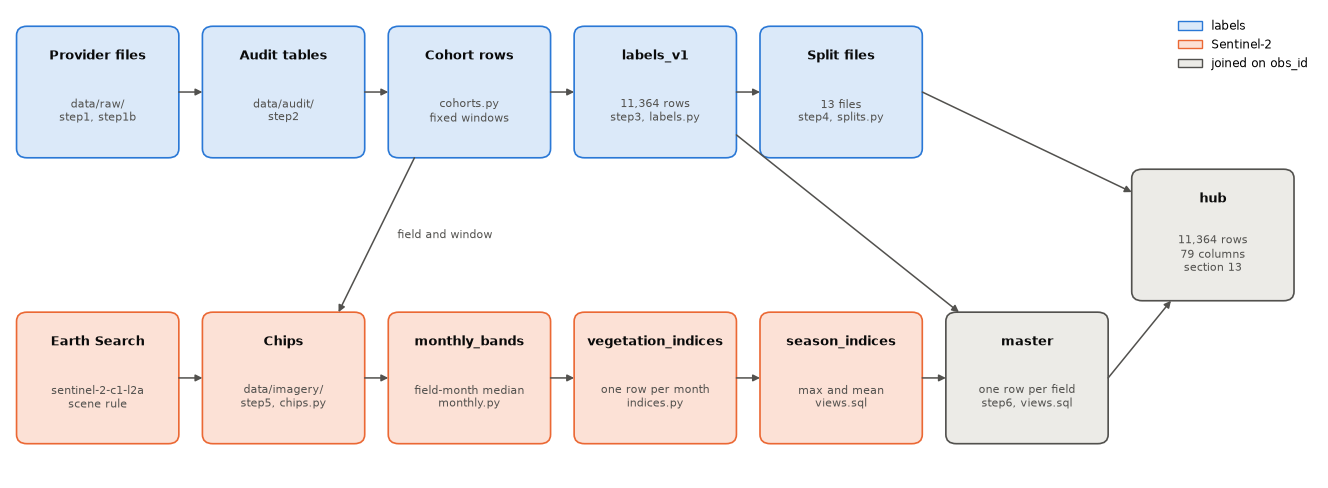

In [35]:
LABEL_LANE = ("#dbe9f9", "#2a78d6")
IMAGE_LANE = ("#fce1d6", "#eb6834")
JOINED = ("#ecebe7", "#52514e")
WIDTH, HEIGHT = 12.4, 11.5


def pipeline_box(axis, x, y, title, note, colours):
    fill, edge = colours
    axis.add_patch(FancyBboxPatch((x, y), WIDTH, HEIGHT, boxstyle="round,pad=0,rounding_size=0.8", facecolor=fill, edgecolor=edge, linewidth=1.2))
    axis.text(x + WIDTH / 2, y + HEIGHT - 2.6, title, ha="center", va="center", fontsize=9.5, fontweight="bold", color="#0b0b0b")
    axis.text(x + WIDTH / 2, y + HEIGHT / 2 - 1.6, note, ha="center", va="center", fontsize=7.8, color="#52514e", linespacing=1.25)


def pipeline_arrow(axis, start, end):
    axis.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "-|>", "color": "#52514e", "linewidth": 1.1, "shrinkA": 0, "shrinkB": 0})


columns = [0.5 + 14.2 * step for step in range(7)]
top, low, middle = 28, 3, 15.5
figure, axis = plt.subplots(figsize=(13.2, 4.8))
axis.set_xlim(0, 100)
axis.set_ylim(0, 41)
axis.axis("off")
figure.patch.set_facecolor("white")

pipeline_box(axis, columns[0], top, "Provider files", "data/raw/\nstep1, step1b", LABEL_LANE)
pipeline_box(axis, columns[1], top, "Audit tables", "data/audit/\nstep2", LABEL_LANE)
pipeline_box(axis, columns[2], top, "Cohort rows", "cohorts.py\nfixed windows", LABEL_LANE)
pipeline_box(axis, columns[3], top, "labels_v1", f"{len(LABELS):,} rows\nstep3, labels.py", LABEL_LANE)
pipeline_box(axis, columns[4], top, "Split files", f"{len(split_manifest['files'])} files\nstep4, splits.py", LABEL_LANE)
pipeline_box(axis, columns[0], low, "Earth Search", f"{downloader.COLLECTION}\nscene rule", IMAGE_LANE)
pipeline_box(axis, columns[1], low, "Chips", "data/imagery/\nstep5, chips.py", IMAGE_LANE)
pipeline_box(axis, columns[2], low, "monthly_bands", "field-month median\nmonthly.py", IMAGE_LANE)
pipeline_box(axis, columns[3], low, "vegetation_indices", "one row per month\nindices.py", IMAGE_LANE)
pipeline_box(axis, columns[4], low, "season_indices", "max and mean\nviews.sql", IMAGE_LANE)
pipeline_box(axis, columns[5], low, "master", "one row per field\nstep6, views.sql", JOINED)
pipeline_box(axis, columns[6], middle, "hub", f"{len(hub):,} rows\n{hub.shape[1]} columns\nsection 13", JOINED)

for left in range(4):
    pipeline_arrow(axis, (columns[left] + WIDTH, top + HEIGHT / 2), (columns[left + 1], top + HEIGHT / 2))
for left in range(5):
    pipeline_arrow(axis, (columns[left] + WIDTH, low + HEIGHT / 2), (columns[left + 1], low + HEIGHT / 2))
pipeline_arrow(axis, (columns[2] + 2, top), (columns[1] + WIDTH - 2, low + HEIGHT))
pipeline_arrow(axis, (columns[3] + WIDTH, top + 2), (columns[5] + 1, low + HEIGHT))
pipeline_arrow(axis, (columns[4] + WIDTH, top + HEIGHT / 2), (columns[6], middle + HEIGHT - 2))
pipeline_arrow(axis, (columns[5] + WIDTH, low + HEIGHT / 2), (columns[6] + 3, middle))
axis.text((columns[1] + columns[2] + WIDTH) / 2 + 1.6, (top + low + HEIGHT) / 2, "field and window", fontsize=8, color="#52514e", ha="left", va="center")
axis.legend(handles=[Patch(facecolor=LABEL_LANE[0], edgecolor=LABEL_LANE[1], label="labels"),
                     Patch(facecolor=IMAGE_LANE[0], edgecolor=IMAGE_LANE[1], label="Sentinel-2"),
                     Patch(facecolor=JOINED[0], edgecolor=JOINED[1], label="joined on obs_id")],
            loc="upper right", ncol=1, frameon=False, fontsize=8.5)
figure.tight_layout(pad=0.4)
display(figure)
plt.close(figure)

## Step 4: X and Y

This step shows what X and Y are, how the full data looks, and every known flaw with a computed count. It fixes no flaw, drops no row, and fits no model.

Run the notebook from the top, because this step reuses the tables of Steps 2 and 3. A cell that needs the database says so and stops. It does not fail.

| Section | Question |
|---|---|
| 1 | What are X and Y? |
| 2 | How do I load them? |
| 3 | How does Y look? |
| 4 | Which features exist? |
| 5 | Where does each cohort come from? |
| 6 | What is missing? |
| 7 | What is wrong with the data? |
| 8 | What must the owner decide? |

### 1. What X and Y are

**File:** `src/cropyield/data/xy.py`.

- **Y** is the yield of one field in one season, in t/ha.
- **X** is the season values of Step 3, section 9. X is the baseline input, not all features. Section 4 lists the other feature families.
- **A row** needs `include_primary` and enough clear months.
- **One cohort at a time.** Each cohort keeps its own yield definition, so `load_xy` takes one cohort, and a model stays inside that cohort.

### 2. The loader

**File:** `src/cropyield/data/xy.py`.

`load_xy(cohort)` gives X and y for one cohort, on the same index, sorted by `obs_id`. It reads the view `master`, and it closes the database at once. On a copy with only some chips, it warns and gives the rows it has.

In [36]:
import warnings
from calendar import month_abbr

from cropyield.data.xy import FEATURES, MIN_CLEAR_MONTHS, load_xy
from step7_check_data import HAZE_BLUE, spearman

EXPECTED_ROWS = {"malawi_2023": 251, "kenya_oaf_2019_2020": 3977, "zimbabwe_lacuna_2022_2023": 1880, "zimbabwe_2024": 2458}
KENYA, MALAWI, LACUNA, ZIMBABWE = "kenya_oaf_2019_2020", "malawi_2023", "zimbabwe_lacuna_2022_2023", "zimbabwe_2024"
NEEDS_DATABASE = "needs the database"

XY = {}
if HAS_DB:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)  # the last lines of this cell state a partial copy
        XY = {cohort: load_xy(cohort, DATA) for cohort in MODEL_COHORTS}
    show(pd.DataFrame([{"cohort": cohort, "rows": len(y), "X shape": f"{X.shape[0]:,} x {X.shape[1]}", "X dtype": str(X.dtypes.iloc[0]),
                        "X index": X.index.name, "y name": y.name, "y dtype": str(y.dtype), "NULL in X": int(X.isna().sum().sum())}
                       for cohort, (X, y) in XY.items()]), "X and y per cohort")
    stage_rows = dict(zip(funnel["cohort"], funnel[MONTHS_STAGE]))
    assert all(len(y) == stage_rows[cohort] for cohort, (_, y) in XY.items()), "load_xy differs from the funnel of Step 3"
    print("The check holds. The rows equal the last column of the funnel in Step 3.")
    if FULL_COPY:
        assert {cohort: len(y) for cohort, (_, y) in XY.items()} == EXPECTED_ROWS
        print(f"The check holds. The rows equal the interface, {sum(EXPECTED_ROWS.values()):,} in all.")
    else:
        print(f"This copy holds {RECORDS:,} records, so X and y hold only those.")
else:
    say_missing()

**X and y per cohort**

| cohort | rows | X shape | X dtype | X index | y name | y dtype | NULL in X |
|---|---|---|---|---|---|---|---|
| malawi_2023 | 251 | 251 x 10 | float64 | obs_id | yield_t_ha | float64 | 0 |
| kenya_oaf_2019_2020 | 3,977 | 3,977 x 10 | float64 | obs_id | yield_t_ha | float64 | 0 |
| zimbabwe_lacuna_2022_2023 | 1,880 | 1,880 x 10 | float64 | obs_id | yield_t_ha | float64 | 0 |
| zimbabwe_2024 | 2,458 | 2,458 x 10 | float64 | obs_id | yield_t_ha | float64 | 0 |

The check holds. The rows equal the last column of the funnel in Step 3.
The check holds. The rows equal the interface, 8,566 in all.


### 3. Y

**Files:** `src/cropyield/data/xy.py`, `labels_v1`.

The unit is t/ha in each cohort, but the yield definition is not the same (Step 3, section 3). So read each panel by itself: the panels share one axis so that you can see the shape, not so that you can compare yields.

The line in each panel marks the mean. Without a database, the table and the figure use the `include_primary` rows, because the clear-month rule cannot run.

**Y per cohort**

| cohort | unit | count | mean | SD | min | median | max | zeros |
|---|---|---|---|---|---|---|---|---|
| malawi_2023 | t/ha | 251 | 2.72 | 1.542 | 0.2 | 2.46 | 8.8 | 0 |
| kenya_oaf_2019_2020 | t/ha | 3,977 | 3.14 | 1.744 | 0 | 2.889 | 10.121 | 74 |
| zimbabwe_lacuna_2022_2023 | t/ha | 1,880 | 3.346 | 1.997 | 0 | 3.019 | 12.43 | 28 |
| zimbabwe_2024 | t/ha | 2,458 | 0.857 | 0.984 | 0.006 | 0.534 | 9.111 | 0 |

The check holds. The zeros equal is_zero of labels_v1.


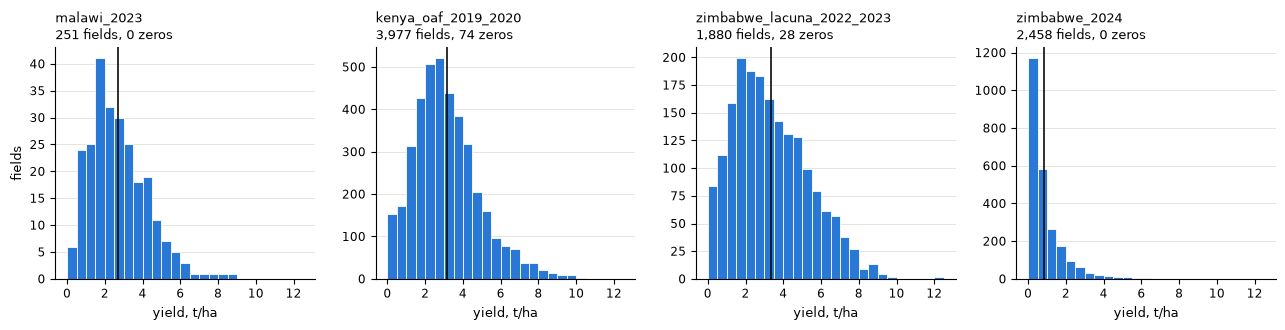

In [37]:
BIN_T_HA = 0.5


def y_of(cohort):
    '''y of one cohort. With no database: the include_primary rows, before the clear-month rule.'''
    if HAS_DB:
        return XY[cohort][1]
    rows = PRIMARY[PRIMARY["cohort"] == cohort].set_index("obs_id")
    return (rows["yield_kg_ha"] / 1000).rename("yield_t_ha")


Y = {cohort: y_of(cohort) for cohort in MODEL_COHORTS}
show(pd.DataFrame([{"cohort": cohort, "unit": "t/ha", "count": len(y), "mean": y.mean(), "SD": y.std(), "min": y.min(),
                    "median": y.median(), "max": y.max(), "zeros": int((y == 0).sum())} for cohort, y in Y.items()]), "Y per cohort")

zero_flags = LABELS.set_index("obs_id")["is_zero"]
assert all(int(zero_flags.loc[y.index].sum()) == int((y == 0).sum()) for y in Y.values()), "zeros differ from labels_v1"
print("The check holds. The zeros equal is_zero of labels_v1.")

bins = np.arange(0, max(y.max() for y in Y.values()) + BIN_T_HA, BIN_T_HA)
figure, axes = plt.subplots(1, len(Y), figsize=(13, 3.4), sharex=True)
for axis, (cohort, y) in zip(axes, Y.items()):
    axis.hist(y, bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.6)
    axis.axvline(y.mean(), color="#0b0b0b", linewidth=1.2)
    axis.set_title(f"{cohort}\n{len(y):,} fields, {int((y == 0).sum())} zeros", fontsize=9.5, loc="left")
    axis.set_xlabel("yield, t/ha", fontsize=9)
    axis.tick_params(labelsize=8.5)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", color="#e5e4df", linewidth=0.7)
    axis.set_axisbelow(True)
axes[0].set_ylabel("fields", fontsize=9)
figure.tight_layout()
display(figure)
plt.close(figure)

### 4. X: the feature families

**Files:** `sql/schema.sql`, `sql/views.sql`.

The first table has one row per feature family in the database. X of section 2 is the row `season_indices`. The other rows wait for their model packets.

- **Shape** is rows x values per row.
- **Null share** is the share of rows with no value. A monthly row is NULL when the month has no clear scene.
- **MOSAIKS and Presto** are not in the same local copy of the team (Step 2). A copy without them shows 0 rows. That is correct.

The second table gives the columns of X: the dtype, then the median per cohort. The unit column of the first table gives their unit.

In [38]:
# family, table, column, unit, time step
FAMILIES = [("Monthly bands", "monthly_bands", "b08", "reflectance, 0 to 1", "month"),
            ("Monthly indices", "vegetation_indices", "ndvi", "no unit", "month"),
            ("Season indices", "season_indices", "ndvi_season_max", "no unit", "season"),
            ("MOSAIKS, month, chip", "mosaiks_monthly", "chip", "no unit", "month"),
            ("MOSAIKS, month, field", "mosaiks_monthly", "field", "no unit", "month"),
            ("MOSAIKS, season, chip", "mosaiks_season", "chip", "no unit", "season"),
            ("MOSAIKS, season, field", "mosaiks_season", "field", "no unit", "season"),
            ("Presto", "presto_embeddings", "embedding", "no unit", "season")]


def family_row(family, table, column, unit, step):
    '''One row of the table: an empty table shows 0 rows and has no null share.'''
    size = sql(f"SELECT count(*) AS n, avg(CAST({column} IS NULL AS DOUBLE)) AS nulls FROM {table}").iloc[0]
    kinds = sql("SELECT column_name, data_type FROM information_schema.columns WHERE table_name = ?", table)
    kind = kinds.loc[kinds["column_name"] == column, "data_type"].iloc[0]
    rows = int(size["n"])
    width = (kinds["data_type"] == "DOUBLE").sum() if kind == "DOUBLE" else sql(f"SELECT max(len({column})) AS k FROM {table}")["k"][0]
    return {"family": family, "table": f"{table}.{column}" if table.startswith(("mosaiks", "presto")) else table,
            "shape": f"{rows:,} x {int(width):,}" if rows else "0 rows", "dtype": kind, "unit": unit,
            "null share": f"{size['nulls']:.1%}" if rows else "", "time step": step}


if HAS_DB:
    show(pd.DataFrame([family_row(*family) for family in FAMILIES]), "One row per feature family")
    show(pd.DataFrame({"X column": FEATURES, "dtype": [str(next(iter(XY.values()))[0][name].dtype) for name in FEATURES],
                       **{f"median, {cohort}": [X[name].median() for name in FEATURES] for cohort, (X, _) in XY.items()}}),
         "The columns of X")
else:
    say_missing()

**One row per feature family**

| family | table | shape | dtype | unit | null share | time step |
|---|---|---|---|---|---|---|
| Monthly bands | monthly_bands | 98,299 x 10 | DOUBLE | reflectance, 0 to 1 | 13.6% | month |
| Monthly indices | vegetation_indices | 98,299 x 5 | DOUBLE | no unit | 13.6% | month |
| Season indices | season_indices | 11,364 x 10 | DOUBLE | no unit | 0.0% | season |
| MOSAIKS, month, chip | mosaiks_monthly.chip | 84,967 x 1,024 | FLOAT[] | no unit | 0.0% | month |
| MOSAIKS, month, field | mosaiks_monthly.field | 84,967 x 1,024 | FLOAT[] | no unit | 0.6% | month |
| MOSAIKS, season, chip | mosaiks_season.chip | 11,364 x 1,024 | FLOAT[] | no unit | 0.0% | season |
| MOSAIKS, season, field | mosaiks_season.field | 11,364 x 1,024 | FLOAT[] | no unit | 0.0% | season |
| Presto | presto_embeddings.embedding | 11,364 x 128 | FLOAT[128] | no unit | 0.0% | season |

**The columns of X**

| X column | dtype | median, malawi_2023 | median, kenya_oaf_2019_2020 | median, zimbabwe_lacuna_2022_2023 | median, zimbabwe_2024 |
|---|---|---|---|---|---|
| ndvi_season_max | float64 | 0.697 | 0.747 | 0.703 | 0.555 |
| ndvi_season_mean | float64 | 0.463 | 0.574 | 0.432 | 0.321 |
| gcvi_season_max | float64 | 3.308 | 4.107 | 3.433 | 2.639 |
| gcvi_season_mean | float64 | 2.222 | 2.915 | 2.135 | 1.639 |
| mtci_season_max | float64 | 3.447 | 4.577 | 4.11 | 3.852 |
| mtci_season_mean | float64 | 2.351 | 3.331 | 2.759 | 2.39 |
| ndvi705_season_max | float64 | 0.462 | 0.515 | 0.458 | 0.366 |
| ndvi705_season_mean | float64 | 0.286 | 0.39 | 0.28 | 0.209 |
| ndvi740_season_max | float64 | 0.091 | 0.112 | 0.108 | 0.099 |
| ndvi740_season_mean | float64 | 0.064 | 0.07 | 0.078 | 0.065 |

### 5. Metadata

**Files:** `labels_v1`, Step 2 for the links.

One row per model cohort, on the `include_primary` rows. The date is `obs_date`: the harvest, crop-cut or photo date (Step 3, section 10). A date far outside the window is a flaw of section 7, so the range shows it.

In [39]:
grids = {}
if HAS_DB:
    grids = dict(sql('''SELECT v.cohort, string_agg(DISTINCT d.crs, ', ' ORDER BY d.crs) AS grids
                        FROM downloads d JOIN labels_v1 v USING (obs_id) GROUP BY v.cohort''').to_numpy())

metadata_rows = []
for cohort, rows in PRIMARY.groupby("cohort", sort=False):
    source = next(item for item in LABEL_SOURCES if cohort in item[3])
    metadata_rows.append({"cohort": cohort, "provider": source[0], "licence": source[2], "rows": len(rows),
                          "first date": rows["obs_date"].min(), "last date": rows["obs_date"].max(),
                          "country": rows["country_iso3"].iloc[0],
                          "latitude": f"{rows['lat'].min():.2f} to {rows['lat'].max():.2f}",
                          "longitude": f"{rows['lon'].min():.2f} to {rows['lon'].max():.2f}",
                          "UTM grids": grids.get(cohort, ""), "admin units": rows["admin_unit"].nunique(),
                          "season window": f"{rows['season_start'].iloc[0]:%d %b} to {rows['season_end'].iloc[0]:%d %b}"})
metadata = pd.DataFrame(metadata_rows)
show(metadata, "One row per cohort")
assert metadata["rows"].sum() == len(PRIMARY), "the metadata rows differ from include_primary"
print("The check holds. The rows add up to include_primary.")

**One row per cohort**

| cohort | provider | licence | rows | first date | last date | country | latitude | longitude | UTM grids | admin units | season window |
|---|---|---|---|---|---|---|---|---|---|---|---|
| malawi_2023 | FAO / NASA Harvest | CC BY | 260 | 17 May 2023 | 26 May 2023 | MWI | -13.43 to -12.53 | 33.21 to 33.87 | EPSG:32736 | 0 | 01 Oct to 30 Jun |
| kenya_oaf_2019_2020 | One Acre Fund | CC BY | 3,977 | 06 Jun 2019 | 02 Feb 2021 | KEN | -1.16 to 1.19 | 34.02 to 37.83 | EPSG:32636, EPSG:32637, EPSG:32736, EPSG:32737 | 50 | 01 Feb to 30 Sep |
| zimbabwe_lacuna_2022_2023 | Lacuna | CC BY 4.0 | 1,880 | 14 Feb 2023 | 01 Jul 2023 | ZWE | -20.96 to -16.41 | 27.21 to 31.88 | EPSG:32735, EPSG:32736 | 20 | 01 Oct to 30 Jun |
| zimbabwe_2024 | Vision-guided yield dataset | CC BY 4.0 | 2,458 | 17 Feb 2024 | 18 Jun 2024 | ZWE | -21.84 to -16.21 | 27.11 to 33.04 | EPSG:32735, EPSG:32736 | 0 | 01 Oct to 30 Jun |

The check holds. The rows add up to include_primary.


### 6. Missing data

**Files:** the table `coverage`, the view `master`.

The heat map gives the share of model fields with a clear scene, per cohort-year and month. It uses the table of Step 3, section 5. A blank cell is outside the window, and it is not zero. A cell at zero inside the window is a month with no clear scene for any field.

The second table counts the rows that the clear-month rule takes out of X and Y. Those rows stay in `labels_v1`.

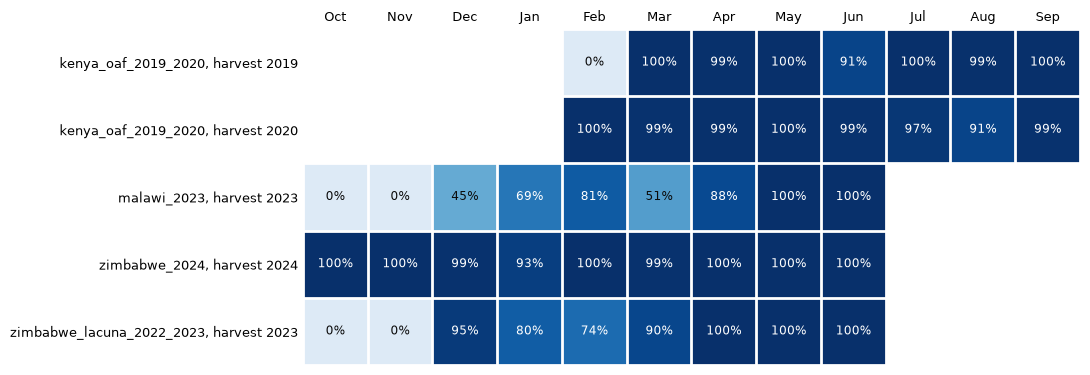

**Rows lost by the rule at 4 clear months**

| cohort | include_primary | rows kept | rows lost | clear months of the lost rows |
|---|---|---|---|---|
| malawi_2023 | 260 | 251 | 9 | 2 months: 1, 3 months: 8 |
| kenya_oaf_2019_2020 | 3,977 | 3,977 | 0 |  |
| zimbabwe_lacuna_2022_2023 | 1,880 | 1,880 | 0 |  |
| zimbabwe_2024 | 2,458 | 2,458 | 0 |  |

The check holds. The rule takes rows from Malawi only.


In [40]:
if HAS_DB:
    order = [10, 11, 12, *range(1, 10)]
    shares = months.assign(place=months["month"].str[5:].astype(int).map(order.index),
                           row=months["cohort"] + ", harvest " + months["year"])
    grid = shares.pivot_table(index="row", columns="place", values="clear share").reindex(columns=range(len(order)))
    figure, axis = plt.subplots(figsize=(11, 0.55 * len(grid) + 1.1))
    axis.imshow(np.ma.masked_invalid(grid.to_numpy()), cmap="Blues", vmin=-0.15, vmax=1, aspect="auto")  # 0 % stays visible against a blank cell
    axis.set_xticks(range(len(order)), [month_abbr[month] for month in order], fontsize=9)
    axis.set_yticks(range(len(grid)), grid.index, fontsize=9)
    axis.xaxis.tick_top()
    axis.set_xticks(np.arange(len(order) + 1) - 0.5, minor=True)
    axis.set_yticks(np.arange(len(grid) + 1) - 0.5, minor=True)
    axis.grid(which="minor", color="white", linewidth=2)
    axis.tick_params(which="both", length=0)
    for row, column in zip(*np.nonzero(grid.notna().to_numpy())):
        share = grid.iat[row, column]
        axis.text(column, row, f"{share:.0%}", ha="center", va="center", fontsize=8.5, color="white" if share > 0.6 else "#0b0b0b")
    axis.spines[:].set_visible(False)
    figure.tight_layout()
    display(figure)
    plt.close(figure)

    clear_months = sql("SELECT cohort, months_with_data AS months FROM master WHERE include_primary")
    lost_rows = []
    for cohort, rows in clear_months.groupby("cohort", sort=False):
        gone = rows.loc[rows["months"] < MIN_CLEAR_MONTHS, "months"].value_counts().sort_index()
        lost_rows.append({"cohort": cohort, "include_primary": len(rows), "rows kept": len(rows) - int(gone.sum()), "rows lost": int(gone.sum()),
                          "clear months of the lost rows": ", ".join(f"{months} months: {count}" for months, count in gone.items())})
    lost = pd.DataFrame(lost_rows)
    show(lost, f"Rows lost by the rule at {MIN_CLEAR_MONTHS} clear months")
    if FULL_COPY:
        assert dict(zip(lost["cohort"], lost["rows lost"])) == {MALAWI: 9, KENYA: 0, LACUNA: 0, ZIMBABWE: 0}
        print("The check holds. The rule takes rows from Malawi only.")
else:
    say_missing()

### 7. Flaws

**Files:** the column `check` of the table names the place to look.

One table holds each known flaw. It has a computed count, the count it is out of, the threat of the project, and a pointer to the check. The next five cells add the rows by theme, and the last cell shows the table. **Nothing here is fixed.** A flaw becomes a robustness row or a later packet. Rows are never picked by a feature after the freeze.

- **Threats:** T-01 spatial leakage, T-02 post-harvest months, T-03 label quality, T-04 location error, T-07 cloud gaps.
- **Kenya signal** is a rank correlation of one feature with yield, on all rows. It is a signal check, not a model score.
- **Which rows.** A count uses the model rows, unless the flaw says other rows. The scene counts use all rows of the cohort, as the table in Step 3, section 6 does.

In [41]:
FLAWS = {}


def add_flaw(theme, flaw, cohort, count, out_of, threat, check):
    '''One row of the table. The key keeps a rerun from adding a row twice.'''
    FLAWS[flaw, cohort] = {"theme": theme, "flaw": flaw, "cohort": cohort, "count": count, "out of": out_of, "threat": threat, "check": check}


def add_per_cohort(theme, flaw, counts, totals, threat, check):
    '''One row per model cohort, from two dictionaries. With no database they are empty.'''
    for cohort in MODEL_COHORTS:
        have = cohort in totals
        add_flaw(theme, flaw, cohort, counts.get(cohort, 0) if have else NEEDS_DATABASE, totals.get(cohort), threat, check)


def cohort_counts(query, *params):
    '''{cohort: count} of a query that gives both columns. With no database it is empty.'''
    return dict(sql(query, *params).to_numpy()) if HAS_DB else {}


# Labels. These counts need no database, except the last one.
kenya_rows = LABELS[LABELS["cohort"] == KENYA]
lacuna_rows = LABELS[LABELS["cohort"] == LACUNA]
malawi_rows = LABELS[LABELS["cohort"] == MALAWI]
zimbabwe_rows = LABELS[LABELS["cohort"] == ZIMBABWE]
nested_ratio = (malawi_rows["cut2_kg_ha"] / malawi_rows["cut1_kg_ha"]).median()

add_flaw("labels", "Impossible dates", KENYA, int(kenya_rows["impossible_date"].sum()), len(kenya_rows), "T-03", "`labels_v1.impossible_date`, `add_cohort_flags` in `src/cropyield/data/labels.py`")
add_flaw("labels", "Provisional Lacuna units", LACUNA, int(lacuna_rows["unit_provisional"].sum()), len(lacuna_rows), "T-03", "`labels_v1.unit_provisional`, Step 3 section 3")
add_flaw("labels", f"Malawi 75 m2 or 100 m2: median nested ratio {nested_ratio:.2f}", MALAWI, int(malawi_rows["cut2_kg_ha"].notna().sum()), len(malawi_rows), "T-03", "`cut1_kg_ha`, `cut2_kg_ha`, Step 3 section 3")
add_per_cohort("labels", "Zero yields in X and Y", {cohort: int((y == 0).sum()) for cohort, y in Y.items()}, {cohort: len(y) for cohort, y in Y.items()}, "T-03", "section 3")
add_flaw("labels", "Kenya 2020 box size is an assumption", KENYA, int((kenya_rows["season_year"] == 2020).sum()), len(kenya_rows), "T-03", "Step 3 section 3")
add_flaw("labels", "Zimbabwe 2024 zero rows left out", ZIMBABWE, int(zimbabwe_rows["is_zero"].sum()), len(zimbabwe_rows), "T-03", "`labels_v1.exclusion_reason`, Step 3 section 2")
add_flaw("labels", "Kenya rows with no date", KENYA, int(kenya_rows["obs_date"].isna().sum()), len(kenya_rows), "T-03", "`labels_v1.obs_date`, Step 3 section 10")
model_rows = sum(len(y) for _, y in XY.values())
add_flaw("labels", "Database rows that no model uses", "all", len(LABELS) - model_rows if HAS_DB else NEEDS_DATABASE, len(LABELS), "none", "`master` minus `load_xy`, Step 3 section 2")
print(f"{len(FLAWS)} rows so far.")

11 rows so far.


In [42]:
# Location
primary_kenya = PRIMARY[PRIMARY["cohort"] == KENYA]
same_point = primary_kenya.groupby(["lat", "lon"]).size()
same_point = same_point[same_point > 1]

if HAS_DB:
    kenya_x, kenya_y = XY[KENYA]
    add_flaw("location", "Kenya fields that never pass NDVI 0.5", KENYA, int((kenya_x["ndvi_season_max"] < 0.5).sum()), len(kenya_x), "T-04", "`master.ndvi_season_max`, `docs/DATA.md`")
    distance = primary_kenya.set_index("obs_id")["site_distance_km"].reindex(kenya_x.index)
    known = distance.notna()
    for name, inside in (("within 2 km", distance <= 2), ("beyond 2 km", distance > 2), ("beyond 5 km", distance > 5)):
        rho = spearman(kenya_y[inside].to_numpy(), kenya_x.loc[inside, "ndvi705_season_max"].to_numpy()) if inside.sum() > 1 else float("nan")
        add_flaw("location", f"Kenya signal {name} of the site point, 2019: Spearman {rho:.2f}", KENYA, int(inside.sum()), int(known.sum()), "T-04", "`labels_v1.site_distance_km`, `spearman` in `scripts/step7_check_data.py`")
else:
    add_flaw("location", "Kenya fields that never pass NDVI 0.5", KENYA, NEEDS_DATABASE, len(primary_kenya), "T-04", "`master.ndvi_season_max`, `docs/DATA.md`")
    add_flaw("location", "Kenya signal by distance to the site point", KENYA, NEEDS_DATABASE, len(primary_kenya), "T-04", "`labels_v1.site_distance_km`, `spearman` in `scripts/step7_check_data.py`")

near = PRIMARY.groupby("cohort")["near_dup_10m"].sum()
add_per_cohort("location", "Near-duplicate points, within 10 m", {cohort: int(near[cohort]) for cohort in MODEL_COHORTS}, {cohort: int((PRIMARY["cohort"] == cohort).sum()) for cohort in MODEL_COHORTS}, "T-01", "`labels_v1.near_dup_10m`, `add_cohort_flags` in `src/cropyield/data/labels.py`")
add_flaw("location", "Overlapping polygons", MALAWI, int(malawi_rows["polygon_overlap_dup"].sum()), len(malawi_rows), "T-01", "`labels_v1.polygon_overlap_dup`, `overlapping_polygons` in `src/cropyield/data/labels.py`")
add_flaw("location", f"Kenya rows on the same coordinates, at {len(same_point)} points", KENYA, int(same_point.sum()), len(primary_kenya), "T-04", "`labels_v1.lat`, `labels_v1.lon`")
for year, rows in primary_kenya.groupby("season_year"):
    add_flaw("location", f"Kenya fields with no site point, {year}", KENYA, int(rows["site_distance_km"].isna().sum()), len(rows), "T-04", "`labels_v1.site_distance_km`")
print(f"{len(FLAWS)} rows so far.")

23 rows so far.


In [43]:
# Time
if HAS_DB:
    march = sql('''SELECT count(*) AS fields, count(*) FILTER (WHERE c.state <> 'clear') AS not_clear
                   FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE v.cohort = ? AND v.include_primary AND c.month = '2023-03' ''', MALAWI).iloc[0]
    add_flaw("time", "Malawi fields with no clear March", MALAWI, int(march["not_clear"]), int(march["fields"]), "T-07", "the table `coverage`, Step 3 section 5")
    february = sql('''SELECT count(*) AS fields, count(*) FILTER (WHERE c.state = 'no_scene') AS none
                      FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE v.cohort = ? AND v.include_primary AND c.month = '2019-02' ''', KENYA).iloc[0]
    add_flaw("time", "Kenya 2019 catalogue gap: no scene in February 2019", KENYA, int(february["none"]), int(february["fields"]), "T-07", "the table `coverage`, Step 3 sections 5 and 9")
    late_2022 = sql('''SELECT v.cohort, count(*) AS field_months, count(*) FILTER (WHERE c.state = 'no_scene') AS none
                       FROM coverage c JOIN labels_v1 v USING (obs_id) WHERE v.include_primary AND c.month IN ('2022-10', '2022-11') GROUP BY v.cohort ORDER BY v.cohort''')
    for row in late_2022.itertuples():
        add_flaw("time", "Field months with no scene in Oct and Nov 2022", row.cohort, int(row.none), int(row.field_months), "T-07", "the table `coverage`, Step 3 section 5")
else:
    add_flaw("time", "Malawi fields with no clear March", MALAWI, NEEDS_DATABASE, None, "T-07", "the table `coverage`, Step 3 section 5")
    add_flaw("time", "Kenya 2019 catalogue gap: no scene in February 2019", KENYA, NEEDS_DATABASE, None, "T-07", "the table `coverage`, Step 3 sections 5 and 9")
    add_flaw("time", "Field months with no scene in Oct and Nov 2022", "all", NEEDS_DATABASE, None, "T-07", "the table `coverage`, Step 3 section 5")

after_harvest = cohort_counts('''SELECT v.cohort, count(*) AS n FROM scenes s JOIN labels_v1 v USING (obs_id)
                                 WHERE v.include_primary AND s.acquired > v.obs_date GROUP BY v.cohort''')
clear_scenes = cohort_counts('''SELECT v.cohort, count(*) AS n FROM scenes s JOIN labels_v1 v USING (obs_id)
                                WHERE v.include_primary GROUP BY v.cohort''')
add_per_cohort("time", "Clear months with a scene after the harvest or cut day", after_harvest, clear_scenes, "T-02", "`scenes.acquired` and `labels_v1.obs_date`, Step 3 section 9")
add_flaw("time", "Kenya harvest after the window ends", KENYA, int((primary_kenya["harvest_date"] > primary_kenya["season_end"]).sum()), len(primary_kenya), "T-02", "`labels_v1.harvest_date`, Step 3 section 5")
print(f"{len(FLAWS)} rows so far.")

32 rows so far.


In [44]:
# Scenes
monthly_mtci = cohort_counts('''SELECT v.cohort, count(*) AS n FROM vegetation_indices m JOIN labels_v1 v USING (obs_id)
                                WHERE v.include_primary AND m.mtci IS NOT NULL GROUP BY v.cohort''')
far_mtci = cohort_counts('''SELECT v.cohort, count(*) AS n FROM vegetation_indices m JOIN labels_v1 v USING (obs_id)
                            WHERE v.include_primary AND abs(m.mtci) > 100 GROUP BY v.cohort''')
add_per_cohort("scenes", "MTCI tails: a monthly value past 100 either way", far_mtci, monthly_mtci, "none", "`vegetation_indices.mtci`, Step 3 section 8")

clear_rows = cohort_counts('''SELECT v.cohort, count(*) AS n FROM monthly_bands b JOIN labels_v1 v USING (obs_id)
                              WHERE v.include_primary AND NOT b.missing GROUP BY v.cohort''')
hazy_rows = cohort_counts('''SELECT v.cohort, count(*) AS n FROM monthly_bands b JOIN labels_v1 v USING (obs_id)
                             WHERE v.include_primary AND NOT b.missing AND b.b02 > ? GROUP BY v.cohort''', HAZE_BLUE)
add_per_cohort("scenes", f"Haze in clear months: field-median blue above {HAZE_BLUE}", hazy_rows, clear_rows, "T-07", "`haze` in `scripts/step7_check_data.py`")

if HAS_DB:
    tried = per_month.groupby("cohort")
    months_tried = {cohort: int(count) for cohort, count in tried.size().items()}
    later_try = {cohort: int(count) for cohort, count in (tried["accepted"].sum() - tried["at_first"].sum()).items()}
    none_passed = {cohort: months_tried[cohort] - int(count) for cohort, count in tried["accepted"].sum().items()}
    add_per_cohort("scenes", "Accepted scene was not the first tried", later_try, months_tried, "T-07", "`per_month`, Step 3 section 6")
    add_per_cohort("scenes", "Months where no scene passed", none_passed, months_tried, "T-07", "`per_month`, Step 3 section 6")
    second_choice = per_month[per_month["after_error"]]
    add_flaw("scenes", f"Second-choice scene after a file error, in {second_choice['obs_id'].nunique()} records", "all", len(second_choice), int(per_month["accepted"].sum()), "none", "`per_month`, Step 3 section 6, compare cell of Step 2")
else:
    add_flaw("scenes", "Accepted scene was not the first tried", "all", NEEDS_DATABASE, None, "T-07", "`per_month`, Step 3 section 6")
    add_flaw("scenes", "Months where no scene passed", "all", NEEDS_DATABASE, None, "T-07", "`per_month`, Step 3 section 6")
    add_flaw("scenes", "Second-choice scene after a file error", "all", NEEDS_DATABASE, None, "none", "`per_month`, Step 3 section 6, compare cell of Step 2")
print(f"{len(FLAWS)} rows so far.")

49 rows so far.


In [45]:
# Splits. These counts need no database.
def nearest_training_km(table, repeat):
    '''The distance from each test row to its nearest training row, in one repeat of a temporal split.'''
    part = table[table["repeat"] == repeat]
    where = places.loc[part["obs_id"]]
    test = (part["fold"] == "test").to_numpy()
    return nearest_km(where["lat"].to_numpy(), where["lon"].to_numpy(), test, ~test)


seasons_of_test = {0: "test on 2020", 1: "test on 2019"}
for repeat, name in seasons_of_test.items():
    gaps_km = nearest_training_km(split_tables[KENYA, "temporal"], repeat)
    add_flaw("splits", f"Kenya new-season test with a training field within 2 km, {name}: {int((gaps_km < 0.01).sum())} within 10 m", KENYA, int((gaps_km < 2).sum()), len(gaps_km), "T-01", "`split_tables`, `nearest_km`, Step 3 section 11")

kenya_region = families[(families["cohort"] == KENYA) & (families["family"] == "s2_region")].iloc[0]
add_flaw("splits", "No training buffer in s2_region: test rows within 2 km of a training row", KENYA, int(kenya_region["test rows within 2 km"]), int(kenya_region["rows"]), "T-01", "Step 3 section 11")
for row in clusters:
    wider = row["groups of s1_cc2km"] - row["the same clusters on model rows"]
    if wider:
        add_flaw("splits", f"Two cluster definitions differ: {row['the same clusters on model rows']} in cluster_2km on model rows, {row['groups of s1_cc2km']} groups in s1_cc2km", row["cohort"], wider, row["groups of s1_cc2km"], "T-01", "Step 3 section 11")
print(f"{len(FLAWS)} rows so far.")

54 rows so far.


In [46]:
flaws = pd.DataFrame(FLAWS.values())
flaws["share"] = [f"{count / out_of:.1%}" if isinstance(count, int) and out_of else "" for count, out_of in zip(flaws["count"], flaws["out of"])]
flaws = flaws.astype({"out of": "object"})[["theme", "flaw", "cohort", "count", "out of", "share", "threat", "check"]]
show(flaws, f"{len(flaws)} rows, each with a computed count")

if FULL_COPY:
    count_of = {key: row["count"] for key, row in FLAWS.items()}
    expected = {("Malawi fields with no clear March", MALAWI): 128, ("Kenya fields that never pass NDVI 0.5", KENYA): 285,
                ("Kenya 2019 catalogue gap: no scene in February 2019", KENYA): 1768,
                ("Field months with no scene in Oct and Nov 2022", MALAWI): 520, ("Field months with no scene in Oct and Nov 2022", LACUNA): 3760,
                ("Clear months with a scene after the harvest or cut day", KENYA): 5633, ("Clear months with a scene after the harvest or cut day", MALAWI): 277,
                ("Clear months with a scene after the harvest or cut day", LACUNA): 3934, ("Clear months with a scene after the harvest or cut day", ZIMBABWE): 6242,
                ("Near-duplicate points, within 10 m", KENYA): 560, ("Near-duplicate points, within 10 m", LACUNA): 22, ("Overlapping polygons", MALAWI): 14,
                ("Impossible dates", KENYA): 13, ("MTCI tails: a monthly value past 100 either way", KENYA): 58, ("Provisional Lacuna units", LACUNA): 2266,
                ("Zero yields in X and Y", KENYA): 74, ("Zero yields in X and Y", LACUNA): 28, ("Database rows that no model uses", "all"): 2798}
    wrong = {key: (count_of.get(key), value) for key, value in expected.items() if count_of.get(key) != value}
    assert not wrong, f"counts differ from the checked values: {wrong}"
    new_season = [row["count"] for key, row in FLAWS.items() if key[0].startswith("Kenya new-season test")]
    assert new_season == [833, 924], new_season
    print(f"The check holds. {len(expected) + len(new_season)} counts equal the values checked on 1 Nov 2026.")

**54 rows, each with a computed count**

| theme | flaw | cohort | count | out of | share | threat | check |
|---|---|---|---|---|---|---|---|
| labels | Impossible dates | kenya_oaf_2019_2020 | 13 | 3,977 | 0.3% | T-03 | `labels_v1.impossible_date`, `add_cohort_flags` in `src/cropyield/data/labels.py` |
| labels | Provisional Lacuna units | zimbabwe_lacuna_2022_2023 | 2,266 | 2,266 | 100.0% | T-03 | `labels_v1.unit_provisional`, Step 3 section 3 |
| labels | Malawi 75 m2 or 100 m2: median nested ratio 1.17 | malawi_2023 | 260 | 260 | 100.0% | T-03 | `cut1_kg_ha`, `cut2_kg_ha`, Step 3 section 3 |
| labels | Zero yields in X and Y | malawi_2023 | 0 | 251 | 0.0% | T-03 | section 3 |
| labels | Zero yields in X and Y | kenya_oaf_2019_2020 | 74 | 3,977 | 1.9% | T-03 | section 3 |
| labels | Zero yields in X and Y | zimbabwe_lacuna_2022_2023 | 28 | 1,880 | 1.5% | T-03 | section 3 |
| labels | Zero yields in X and Y | zimbabwe_2024 | 0 | 2,458 | 0.0% | T-03 | section 3 |
| labels | Kenya 2020 box size is an assumption | kenya_oaf_2019_2020 | 2,209 | 3,977 | 55.5% | T-03 | Step 3 section 3 |
| labels | Zimbabwe 2024 zero rows left out | zimbabwe_2024 | 1,874 | 4,332 | 43.3% | T-03 | `labels_v1.exclusion_reason`, Step 3 section 2 |
| labels | Kenya rows with no date | kenya_oaf_2019_2020 | 89 | 3,977 | 2.2% | T-03 | `labels_v1.obs_date`, Step 3 section 10 |
| labels | Database rows that no model uses | all | 2,798 | 11,364 | 24.6% | none | `master` minus `load_xy`, Step 3 section 2 |
| location | Kenya fields that never pass NDVI 0.5 | kenya_oaf_2019_2020 | 285 | 3,977 | 7.2% | T-04 | `master.ndvi_season_max`, `docs/DATA.md` |
| location | Kenya signal within 2 km of the site point, 2019: Spearman 0.29 | kenya_oaf_2019_2020 | 966 | 1,706 | 56.6% | T-04 | `labels_v1.site_distance_km`, `spearman` in `scripts/step7_check_data.py` |
| location | Kenya signal beyond 2 km of the site point, 2019: Spearman 0.17 | kenya_oaf_2019_2020 | 740 | 1,706 | 43.4% | T-04 | `labels_v1.site_distance_km`, `spearman` in `scripts/step7_check_data.py` |
| location | Kenya signal beyond 5 km of the site point, 2019: Spearman 0.07 | kenya_oaf_2019_2020 | 211 | 1,706 | 12.4% | T-04 | `labels_v1.site_distance_km`, `spearman` in `scripts/step7_check_data.py` |
| location | Near-duplicate points, within 10 m | malawi_2023 | 4 | 260 | 1.5% | T-01 | `labels_v1.near_dup_10m`, `add_cohort_flags` in `src/cropyield/data/labels.py` |
| location | Near-duplicate points, within 10 m | kenya_oaf_2019_2020 | 560 | 3,977 | 14.1% | T-01 | `labels_v1.near_dup_10m`, `add_cohort_flags` in `src/cropyield/data/labels.py` |
| location | Near-duplicate points, within 10 m | zimbabwe_lacuna_2022_2023 | 22 | 1,880 | 1.2% | T-01 | `labels_v1.near_dup_10m`, `add_cohort_flags` in `src/cropyield/data/labels.py` |
| location | Near-duplicate points, within 10 m | zimbabwe_2024 | 2 | 2,458 | 0.1% | T-01 | `labels_v1.near_dup_10m`, `add_cohort_flags` in `src/cropyield/data/labels.py` |
| location | Overlapping polygons | malawi_2023 | 14 | 260 | 5.4% | T-01 | `labels_v1.polygon_overlap_dup`, `overlapping_polygons` in `src/cropyield/data/labels.py` |
| location | Kenya rows on the same coordinates, at 95 points | kenya_oaf_2019_2020 | 203 | 3,977 | 5.1% | T-04 | `labels_v1.lat`, `labels_v1.lon` |
| location | Kenya fields with no site point, 2019 | kenya_oaf_2019_2020 | 62 | 1,768 | 3.5% | T-04 | `labels_v1.site_distance_km` |
| location | Kenya fields with no site point, 2020 | kenya_oaf_2019_2020 | 2,209 | 2,209 | 100.0% | T-04 | `labels_v1.site_distance_km` |
| time | Malawi fields with no clear March | malawi_2023 | 128 | 260 | 49.2% | T-07 | the table `coverage`, Step 3 section 5 |
| time | Kenya 2019 catalogue gap: no scene in February 2019 | kenya_oaf_2019_2020 | 1,768 | 1,768 | 100.0% | T-07 | the table `coverage`, Step 3 sections 5 and 9 |
| time | Field months with no scene in Oct and Nov 2022 | malawi_2023 | 520 | 520 | 100.0% | T-07 | the table `coverage`, Step 3 section 5 |
| time | Field months with no scene in Oct and Nov 2022 | zimbabwe_lacuna_2022_2023 | 3,760 | 3,760 | 100.0% | T-07 | the table `coverage`, Step 3 section 5 |
| time | Clear months with a scene after the harvest or cut day | malawi_2023 | 277 | 1,387 | 20.0% | T-02 | `scenes.acquired` and `labels_v1.obs_date`, Step 3 section 9 |
| time | Clear months with a scene after the harvest or cut day | kenya_oaf_2019_2020 | 5,633 | 29,482 | 19.1% | T-02 | `scenes.acquired` and `labels_v1.obs_date`, Step 3 section 9 |
| time | Clear months with a scene after the harvest or cut day | zimbabwe_lacuna_2022_2023 | 3,934 | 12,010 | 32.8% | T-02 | `scenes.acquired` and `labels_v1.obs_date`, Step 3 section 9 |
| time | Clear months with a scene after the harvest or cut day | zimbabwe_2024 | 6,242 | 21,883 | 28.5% | T-02 | `scenes.acquired` and `labels_v1.obs_date`, Step 3 section 9 |
| time | Kenya harvest after the window ends | kenya_oaf_2019_2020 | 850 | 3,977 | 21.4% | T-02 | `labels_v1.harvest_date`, Step 3 section 5 |
| scenes | MTCI tails: a monthly value past 100 either way | malawi_2023 | 0 | 1,387 | 0.0% | none | `vegetation_indices.mtci`, Step 3 section 8 |
| scenes | MTCI tails: a monthly value past 100 either way | kenya_oaf_2019_2020 | 58 | 29,482 | 0.2% | none | `vegetation_indices.mtci`, Step 3 section 8 |
| scenes | MTCI tails: a monthly value past 100 either way | zimbabwe_lacuna_2022_2023 | 27 | 12,010 | 0.2% | none | `vegetation_indices.mtci`, Step 3 section 8 |
| scenes | MTCI tails: a monthly value past 100 either way | zimbabwe_2024 | 51 | 21,883 | 0.2% | none | `vegetation_indices.mtci`, Step 3 section 8 |
| scenes | Haze in clear months: field-median blue above 0.15 | malawi_2023 | 32 | 1,387 | 2.3% | T-07 | `haze` in `scripts/step7_check_data.py` |
| scenes | Haze in clear months: field-median blue above 0.15 | kenya_oaf_2019_2020 | 269 | 29,482 | 0.9% | T-07 | `haze` in `scripts/step7_check_data.py` |
| scenes | Haze in clear months: field-median blue above 0.15 | zimbabwe_lacuna_2022_2023 | 182 | 12,010 | 1.5% | T-07 | `haze` in `scripts/step7_check_data.py` |
| scenes | Haze in clear months: field-median blue above 0.15 | zimbabwe_2024 | 403 | 21,883 | 1.8% | T-07 | `haze` in `scripts/step7_check_data.py` |
| scenes | Accepted scene was not the first tried | malawi_2023 | 230 | 1,820 | 12.6% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Accepted scene was not the first tried | kenya_oaf_2019_2020 | 1,898 | 30,048 | 6.3% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Accepted scene was not the first tried | zimbabwe_lacuna_2022_2023 | 962 | 15,337 | 6.3% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Accepted scene was not the first tried | zimbabwe_2024 | 1,118 | 38,988 | 2.9% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Months where no scene passed | malawi_2023 | 433 | 1,820 | 23.8% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Months where no scene passed | kenya_oaf_2019_2020 | 566 | 30,048 | 1.9% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Months where no scene passed | zimbabwe_lacuna_2022_2023 | 1,348 | 15,337 | 8.8% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Months where no scene passed | zimbabwe_2024 | 470 | 38,988 | 1.2% | T-07 | `per_month`, Step 3 section 6 |
| scenes | Second-choice scene after a file error, in 9 records | all | 10 | 84,967 | 0.0% | none | `per_month`, Step 3 section 6, compare cell of Step 2 |
| splits | Kenya new-season test with a training field within 2 km, test on 2020: 10 within 10 m | kenya_oaf_2019_2020 | 833 | 2,209 | 37.7% | T-01 | `split_tables`, `nearest_km`, Step 3 section 11 |
| splits | Kenya new-season test with a training field within 2 km, test on 2019: 12 within 10 m | kenya_oaf_2019_2020 | 924 | 1,768 | 52.3% | T-01 | `split_tables`, `nearest_km`, Step 3 section 11 |
| splits | No training buffer in s2_region: test rows within 2 km of a training row | kenya_oaf_2019_2020 | 806 | 3,977 | 20.3% | T-01 | Step 3 section 11 |
| splits | Two cluster definitions differ: 272 in cluster_2km on model rows, 289 groups in s1_cc2km | zimbabwe_lacuna_2022_2023 | 17 | 289 | 5.9% | T-01 | Step 3 section 11 |
| splits | Two cluster definitions differ: 956 in cluster_2km on model rows, 996 groups in s1_cc2km | zimbabwe_2024 | 40 | 996 | 4.0% | T-01 | Step 3 section 11 |

The check holds. 20 counts equal the values checked on 1 Nov 2026.


### 8. Open decisions

**Files:** `docs/DATA.md`, `docs/EVALUATION.md`, `docs/DECISIONS.md`.

The data foundation ends here. Only the owner can rule on these points, and each one waits for that ruling. No code changes before it.

| Decision | Options | See |
|---|---|---|
| **Zero yields.** Is a zero a yield or an exclusion? | Keep the zeros, or add a row without them | Section 3 |
| **Malawi cut area.** The main cut may be smaller than its nominal area. | Keep the provider's value, or rescale in a robustness row | Step 3, section 3 |
| **Kenya 2020 box size.** The provider does not state it. | Keep the assumption, or ask the provider | Step 3, section 3 |
| **Training buffer.** No split file has one. | Stay with whole held-out regions, or add a step that drops near training rows | Step 3, section 11 |
| **New-season test.** It is not blocked in space. | Report it with this warning, or add a blocked test set | Step 3, section 11 |
| **Second-choice records.** A few records hold a second scene after a file error. | Keep the frozen list, or refresh those records | Step 2 and Step 3, section 6 |